In [2]:
library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


Loading required package: SeuratObject

Loading required package: sp


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Loading required package: Rcpp


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become erro

## scIBD data

In [2]:
scIBD <- readRDS("scIBD.gex_matrix_raw.rds")
dim(scIBD)
head(scIBD@meta.data)

[1]   16105 1138625

,sample,subject,study,nUMI,nGene,rp_pct,mt_pct,minor_cluster,major_cluster,UMAP_1,⋯,TSNE_1,TSNE_2,gUMAP_1,gUMAP_2,gTSNE_1,gTSNE_2,stage,tissue,tissue.sub,disease
,<chr>,<chr>,<fct>,<int>,<int>,<dbl>,<dbl>,<fct>,<fct>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>
GSM3140593_AAACCTGCATGCCCGA-1,GSM3140593,GSM3140593_HC1,"Kinchen et al., Cell, 2018",1786,731,15.285555,4.143337,Stromal 2,Mesenchymal,10.96636,⋯,-29.84958,12.84185,13.17873,13.92877,3.634667,26.02885,adult,largeInt,colon,Healthy
GSM3140593_AAACCTGTCAGCCTAA-1,GSM3140593,GSM3140593_HC1,"Kinchen et al., Cell, 2018",3660,1224,29.890710,4.098361,Stromal 1,Mesenchymal,11.89204,⋯,-33.21410,49.88260,13.00563,18.60729,4.716939,-29.48881,adult,largeInt,colon,Healthy
GSM3140593_AAACCTGTCGGTTAAC-1,GSM3140593,GSM3140593_HC1,"Kinchen et al., Cell, 2018",3747,1368,25.006672,6.351748,Stromal 1,Mesenchymal,10.57655,⋯,-35.41550,50.87022,12.73609,17.63619,4.576714,-29.57353,adult,largeInt,colon,Healthy
GSM3140593_AAACCTGTCTGTGCAA-1,GSM3140593,GSM3140593_HC1,"Kinchen et al., Cell, 2018",7610,2263,20.775295,2.522996,Stromal 1,Mesenchymal,11.99664,⋯,-39.61334,51.15045,13.13132,18.72797,5.223072,-30.10283,adult,largeInt,colon,Healthy
GSM3140593_AAACCTGTCTTAGCCC-1,GSM3140593,GSM3140593_HC1,"Kinchen et al., Cell, 2018",2291,852,11.741597,12.832824,Stromal 1,Mesenchymal,11.16731,⋯,-42.47762,37.80541,12.64923,16.09705,-16.000875,-13.62523,adult,largeInt,colon,Healthy
GSM3140593_AAACGGGAGATCCCGC-1,GSM3140593,GSM3140593_HC1,"Kinchen et al., Cell, 2018",1485,599,9.494949,8.215488,Stromal 1,Mesenchymal,11.69730,⋯,-46.35890,37.66824,12.61992,15.20794,-15.589691,-12.79098,adult,largeInt,colon,Healthy


ERROR: [1m[33mError[39m in `DefaultDimReduc()`:[22m
[33m![39m Unable to find a DimReduc matching one of 'umap', 'tsne', or 'pca'; please specify a dimensional reduction to use


PC_ 1 
Positive:  KRT8, EPCAM, PHGR1, LGALS4, KRT18, CLDN3, CLDN7, FABP1, CLDN4, FXYD3 
	   LGALS3, TSPAN8, KRT19, S100A14, ELF3, C19orf33, SMIM22, C15orf48, AGR2, PRSS3 
	   AMN, AGR3, CKB, MISP, MT1G, CDX1, CDH17, TMEM54, MUC13, PRSS8 
Negative:  CD74, CD7, HLA-DPA1, HLA-DPB1, GPR183, HLA-DQA1, PIM2, MS4A1, CD79B, HLA-DQB1 
	   RGCC, CD83, LY9, VPREB3, CST7, HLA-DRA, NKG7, IGHM, IGKC, POU2F2 
	   BANK1, GPR65, MZB1, CCR7, CD19, HLA-DMA, GZMA, IGHA1, CTSW, POU2AF1 
PC_ 2 
Positive:  CD74, PLAC8, MT-CO2, PHGR1, LGALS4, EPCAM, C15orf48, SMIM22, CD7, SPINT2 
	   FXYD3, CLDN7, HLA-DRB1, CLDN3, HLA-DRA, PIGR, HLA-DQB1, HLA-DPA1, TSPAN1, PIM2 
	   FABP1, KRT19, S100A14, HLA-DQA1, MS4A1, ELF3, C19orf33, FAM3D, CLDN4, GPR183 
Negative:  CALD1, COL3A1, SPARC, COL1A2, COL1A1, COL6A2, MFAP4, PTN, COL6A1, TPM2 
	   DCN, FSTL1, SERPINH1, MEG3, RBP1, SPARCL1, MMP2, IGFBP7, FBLN1, TCF21 
	   PMP22, PCOLCE, LUM, CXCL12, COL5A2, COL6A3, OLFML3, MYL9, FHL1, EMILIN1 
PC_ 3 
Positive:  A2M, TM4SF1, PLVAP

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1138625
Number of edges: 28984783

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9390
Number of communities: 86
Elapsed time: 2192 seconds


35 singletons identified. 51 final clusters.

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



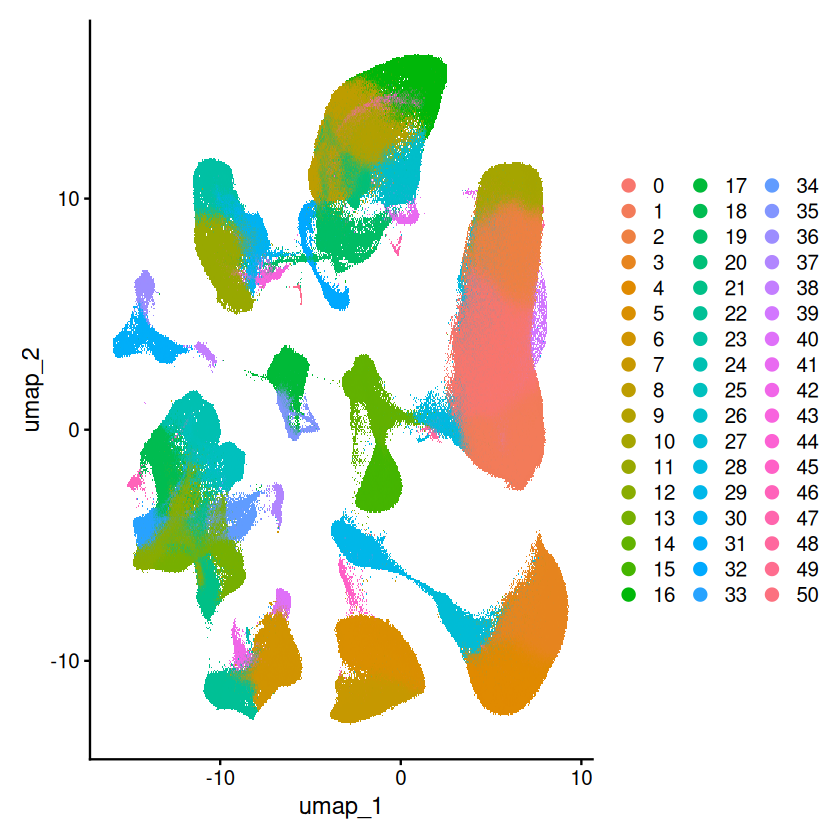

In [3]:
scIBD <- NormalizeData(scIBD, verbose = FALSE)
scIBD <- FindVariableFeatures(scIBD, nfeatures = 3000, verbose = FALSE)
scIBD <- ScaleData(scIBD, features = VariableFeatures(scIBD), verbose = FALSE)
scIBD <- RunPCA(scIBD, dims = 1:20)
scIBD <- RunUMAP(scIBD, reduction = "pca", dims = 1:20)
scIBD <- FindNeighbors(scIBD, dims = 1:20)
scIBD <- FindClusters(scIBD, resolution = 1)
DimPlot(scIBD)

In [4]:
saveRDS(scIBD, file = "scIBD_whole.rds")

Found more than one class "package_version" in cache; using the first, from namespace 'SeuratObject'

Also defined by ‘alabaster.base’

Found more than one class "package_version" in cache; using the first, from namespace 'SeuratObject'

Also defined by ‘alabaster.base’



Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



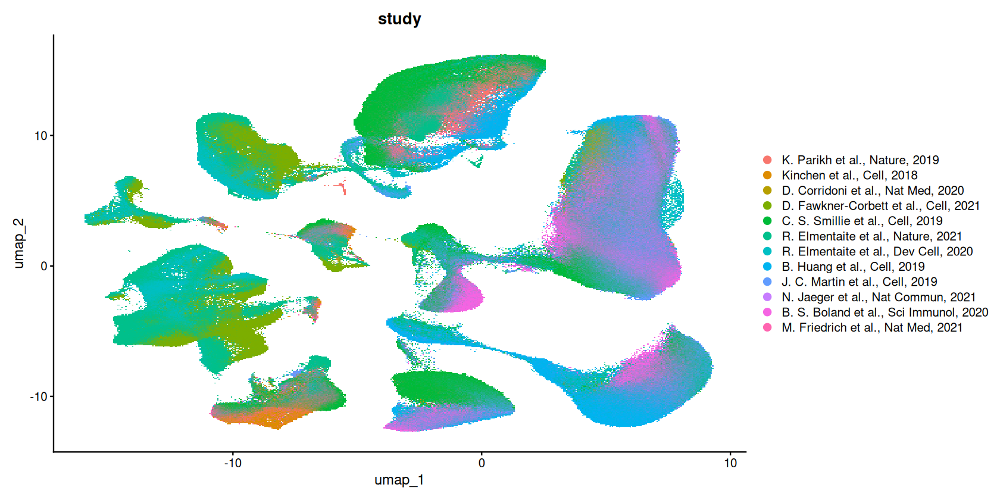

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



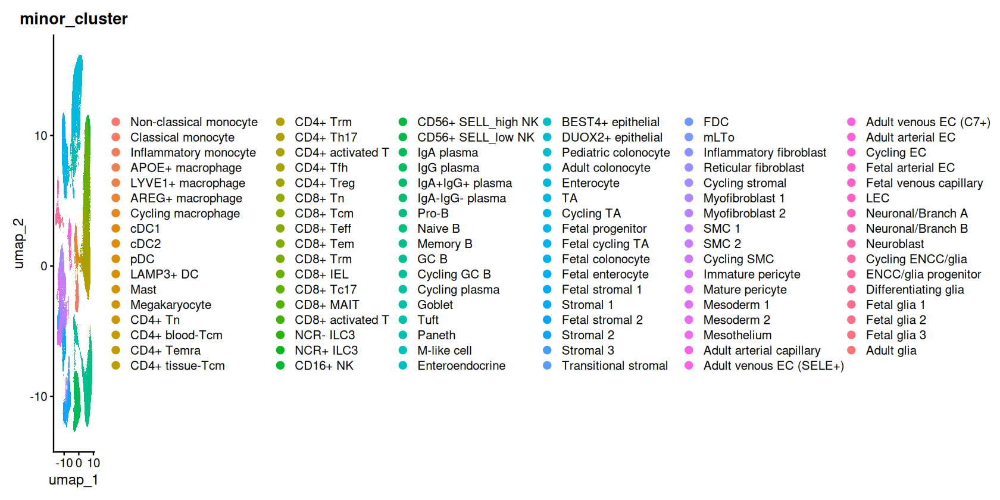

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



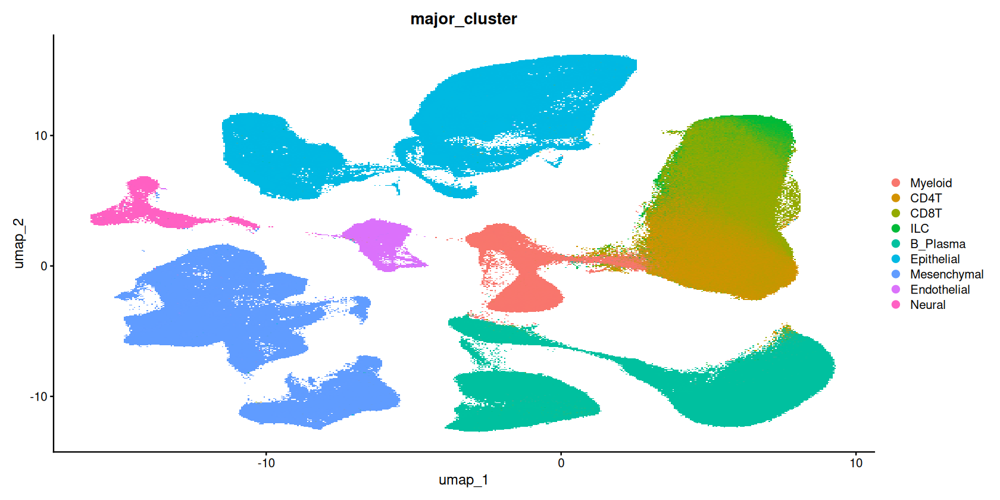

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



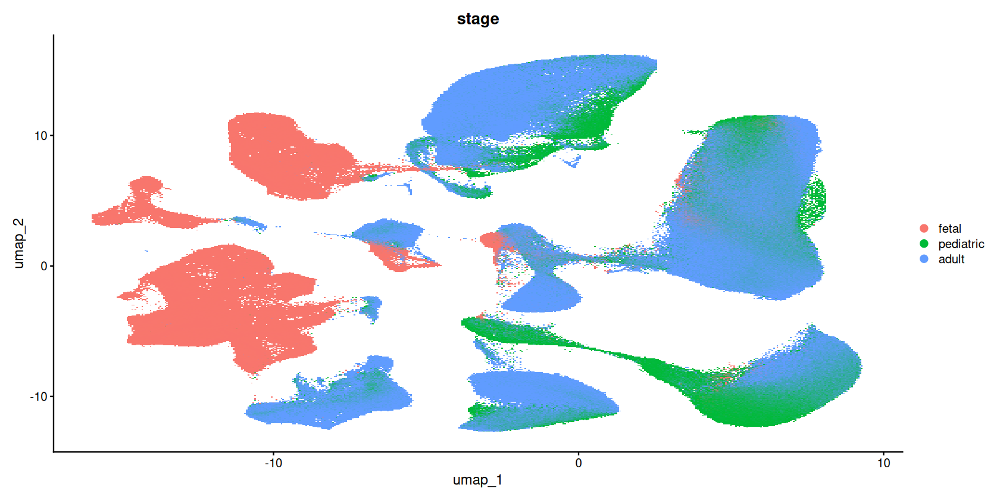

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



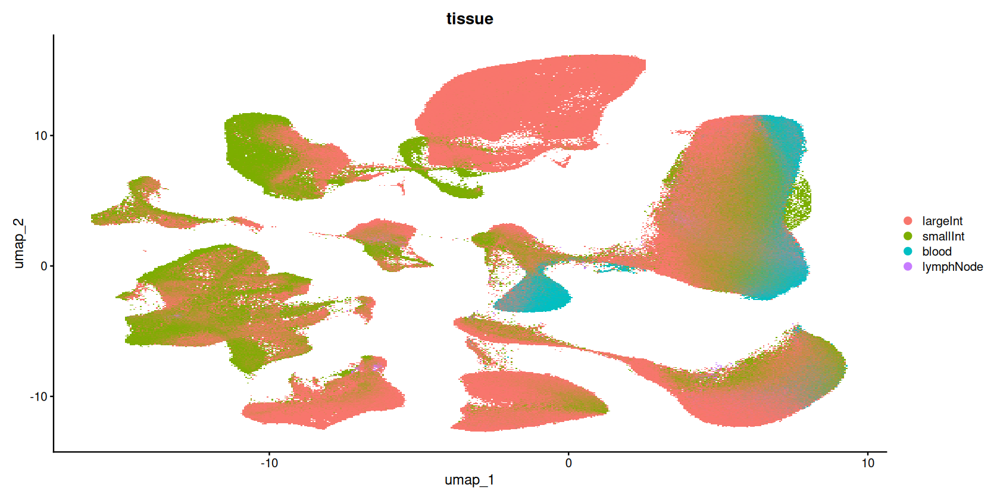

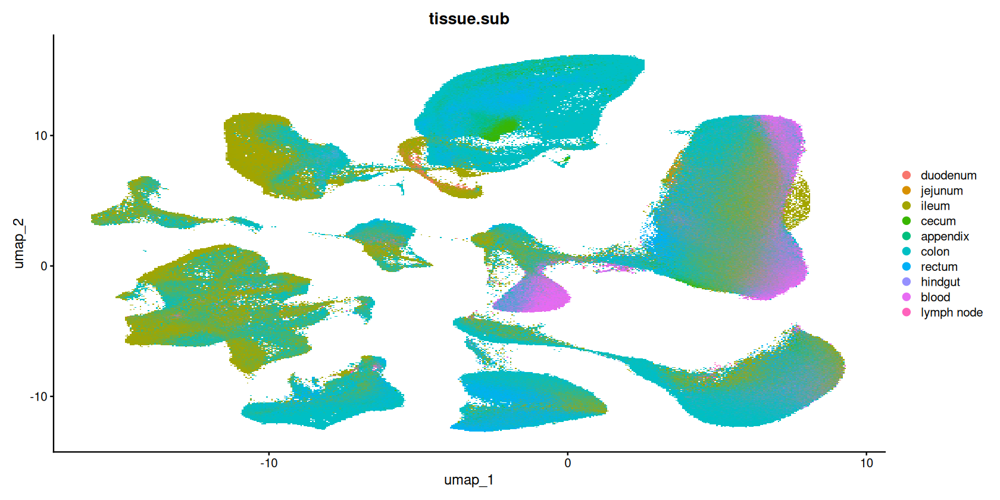

In [5]:
# Exploring dataset
options(repr.plot.width = 14)
DimPlot(scIBD, group.by = "study")
DimPlot(scIBD, group.by = "minor_cluster")
DimPlot(scIBD, group.by = "major_cluster")
DimPlot(scIBD, group.by = "stage")
DimPlot(scIBD, group.by = "tissue")
DimPlot(scIBD, group.by = "tissue.sub")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



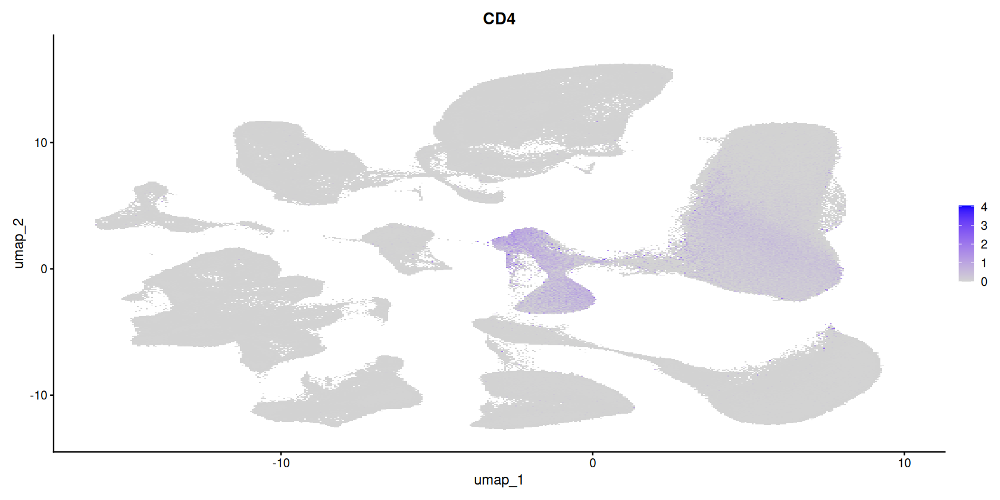

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



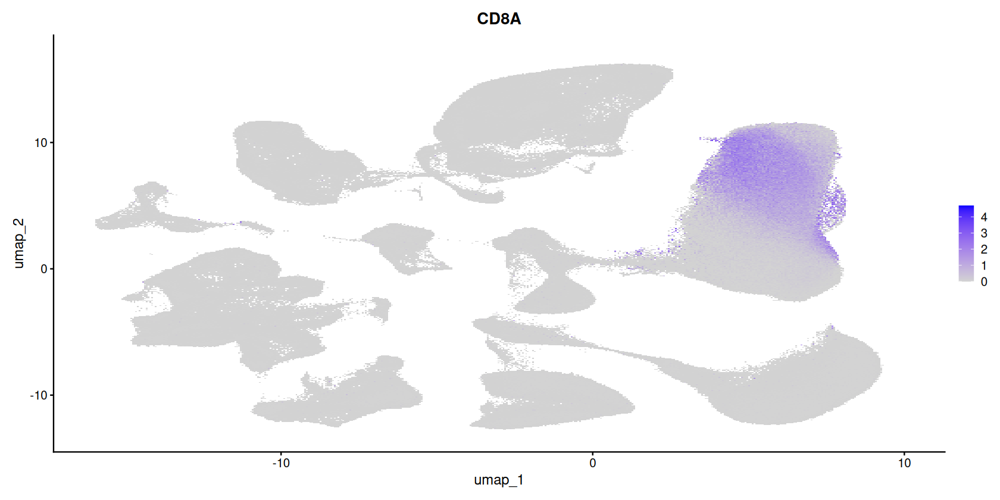

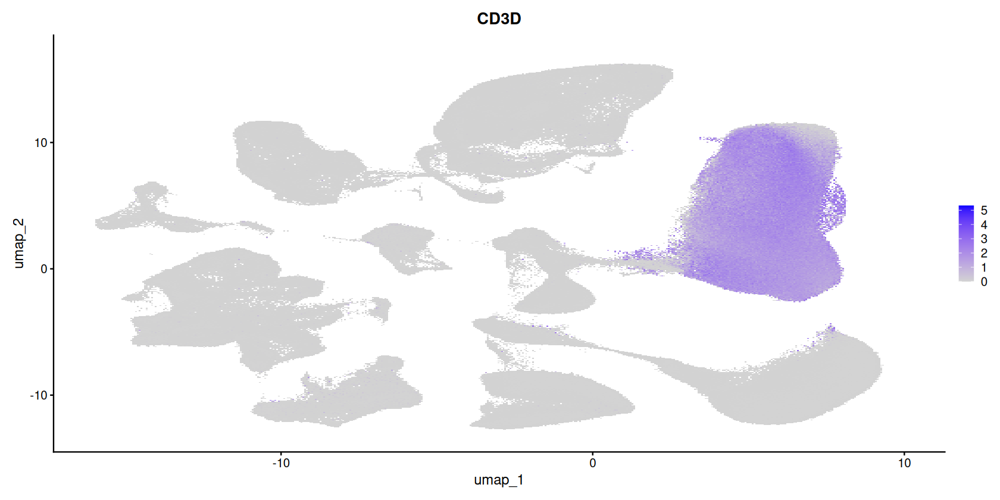

In [6]:
FeaturePlot(scIBD, features = "CD4")
FeaturePlot(scIBD, features = "CD8A")
FeaturePlot(scIBD, features = "CD3D")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



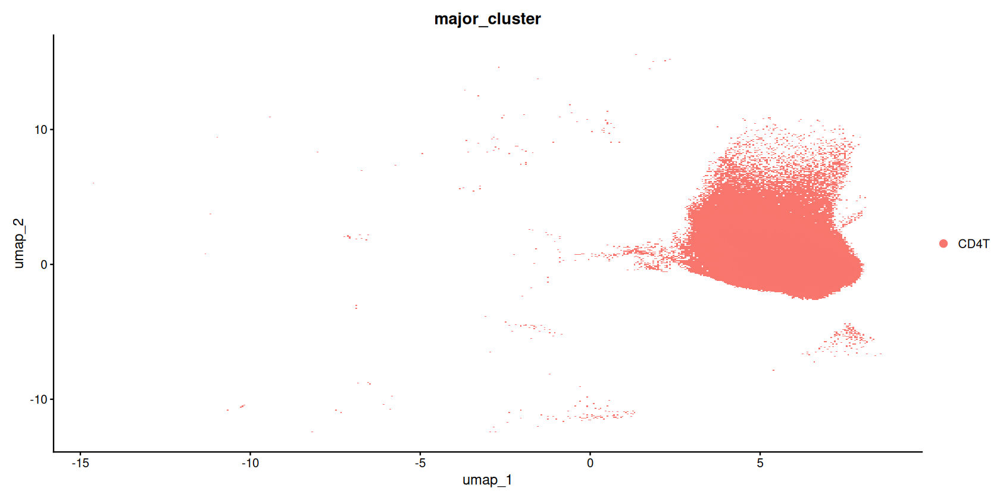

In [8]:
# Subseting for CD4 cells
scIBD_CD4 <- subset(scIBD, major_cluster == c("CD4T"))
DimPlot(scIBD_CD4, group.by = "major_cluster", reduction = "umap")

Warning message in PrepDR(object = object, features = features, verbose = verbose):
“The following 1606 features requested have not been scaled (running reduction without them): HSPA1B, EGR1, CCL5, ID3, JUN, ENTPD2, DNAJB1, FOS, RGS1, NR4A1, HSP90AA1, LGALS1, ZFP36, DUSP2, KLRB1, KLF2, GAPDH, RPS17, CDO1, MT-ATP8, LMNA, CD69, SAT1, ANXA1, FOSB, CREM, PTMS, FAIM2, CITED2, IFITM1, PTPRCAP, CD55, ACTB, YBX3, NFKBIA, TNFAIP3, IER2, TSPAN12, HSPD1, RPS26, RPS10, CRYBB1, DUSP1, KLF6, NR4A2, ACTG1, IGFL2, MAGEH1, ID2, SLC7A10, SLC28A3, GADD45B, SLC2A3, HBQ1, DGKI, RGS2, EZR, SRGN, TSC22D1, CXCR4, JUNB, PKM, ZNF331, RPL21, HSPE1, PMAIP1, HSP90AB1, CBLN3, DDIT4, IRF1, ITM2A, MYADM, MT-ND4L, HSPB1, UCP2, SELL, EEF1G, ZACN, LTB, PGAM1, ZFP36L1, VIM, RPS29, GAD1, HAL, RPL13A, DOK5, ZEB2, S100A4, HSPA5, PHACTR3, PFN1, IL32, COTL1, PIM3, LYPD3, RPS20, VPS37B, PGM2L1, HSPA8, PPP1R15A, EPHB6, FAM177A1, RTKN2, ODC1, ENO1, BMPER, ITGB1, NFKBIZ, CEACAM4, H1FX, RNF19A, CLEC2B, TXNIP, NBEAL1, RPS4Y1, CISH,

PC_ 1 
Positive:  CTLA4, TNFRSF18, BATF, TNFRSF1B, ICOS, TNFRSF4, TIGIT, DUSP4, LAG3, PHLDA1 
	   IL2RB, GK, CDKN1A, CTSC, PDCD1, CD74, MAF, CXCR6, STX11, SH2D2A 
	   TOX2, FOXP3, MAP3K8, RAB11FIP1, CST7, GEM, ICA1, MIR155HG, INSIG1, IL2RA 
Negative:  C1orf162, TRABD2A, LEF1, MAL, PLAC8, NELL2, S100A9, CCR7, S1PR1, ATXN8OS 
	   CRIP2, TCEA3, SLC40A1, ITGA6, ZNF90, S100A8, AIF1, SVIL, MYC, LPAR6 
	   TSHZ2, MTRNR2L10, NOG, S100A10, NEFL, CTSW, FBLN5, PI16, FXYD7, FAM13A 
PC_ 2 
Positive:  IGHA1, IGKC, IGLC3, IGLC2, IGHM, IGHG3, ZNF90, MTRNR2L10, S100A6, GPR171 
	   CXCR6, TFF3, CCL20, PRDM1, IGHA2, HLA-DRA, CXCL14, CCL4, GZMA, ATXN8OS 
	   MTRNR2L1, U2AF1, ANKRD28, DEFA5, TNFSF13B, IGHG4, MRPL23, LGALS3, CST7, PHGR1 
Negative:  NME2, MT-CO2, LIME1, LEF1, MTRNR2L12, POLD4, HIST1H4C, FAAH2, CRIP1, CCR7 
	   BACH2, S1PR1, TUBA1A, MAL, HIST1H1E, TRBV20-1, RHOB, NELL2, H2AFX, DBNDD2 
	   ITGA6, PASK, TRBV5-1, CYP51A1, TRAV8-2, SGK1, LIMS2, CXCR5, AQP3, TOB1 
PC_ 3 
Positive:  TNF, MTRNR2L12,

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 188965
Number of edges: 4395956

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8595
Number of communities: 32
Elapsed time: 111 seconds


7 singletons identified. 25 final clusters.

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



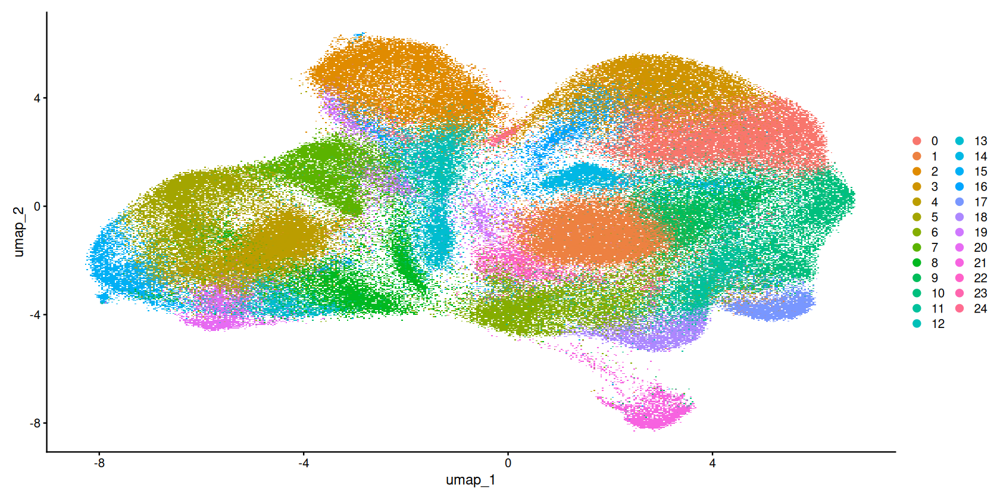

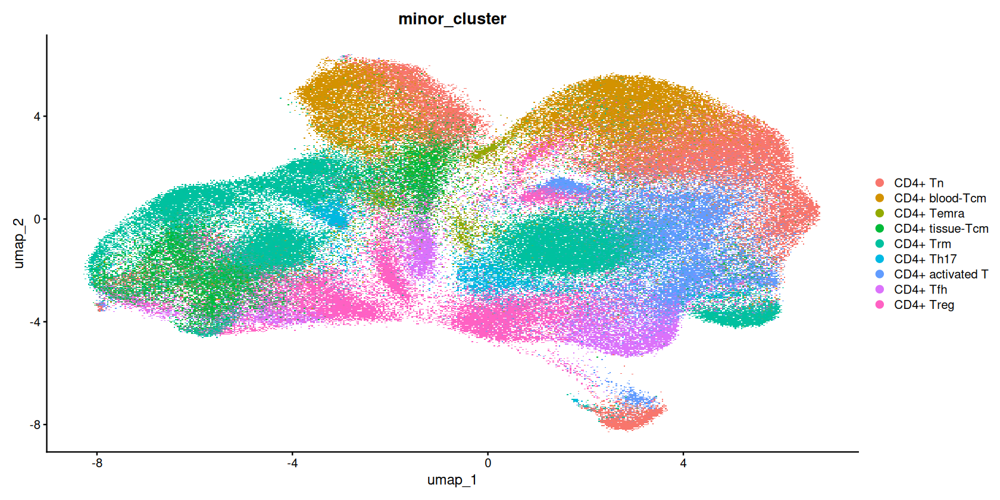

In [9]:
scIBD_CD4 <- NormalizeData(scIBD_CD4, verbose = FALSE)
scIBD_CD4 <- FindVariableFeatures(scIBD_CD4, nfeatures = 3000, verbose = FALSE)
scIBD_CD4 <- ScaleData(scIBD_CD4, features = VariableFeatures(scIBD), verbose = FALSE)
scIBD_CD4 <- RunPCA(scIBD_CD4, dims = 1:20)
scIBD_CD4 <- RunUMAP(scIBD_CD4, reduction = "pca", dims = 1:20)
scIBD_CD4 <- FindNeighbors(scIBD_CD4, dims = 1:20)
scIBD_CD4 <- FindClusters(scIBD_CD4, resolution = 1)
DimPlot(scIBD_CD4, reduction = "umap")
DimPlot(scIBD_CD4, group.by = "minor_cluster", reduction = "umap")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



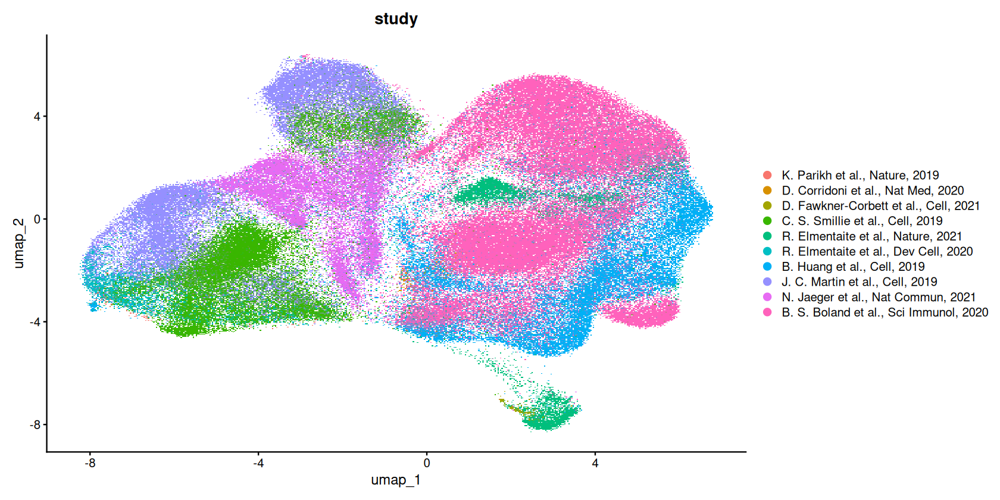

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



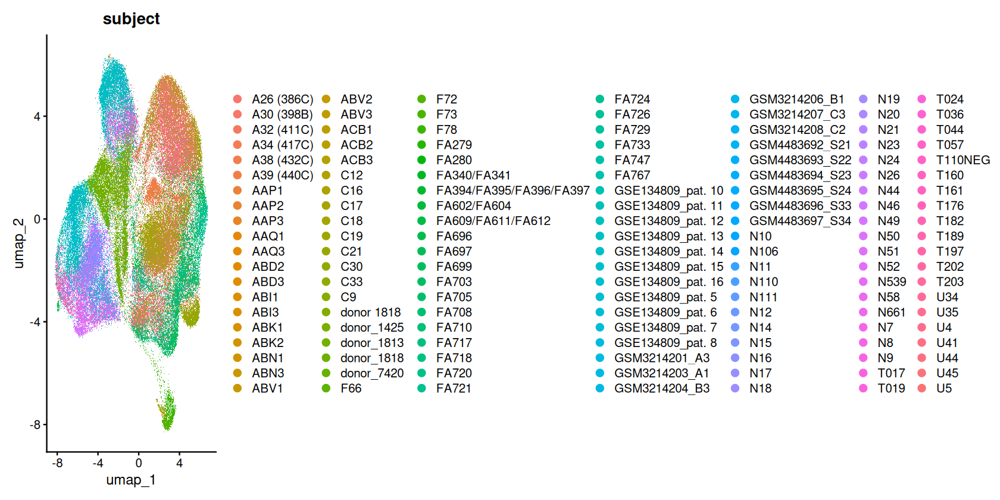

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



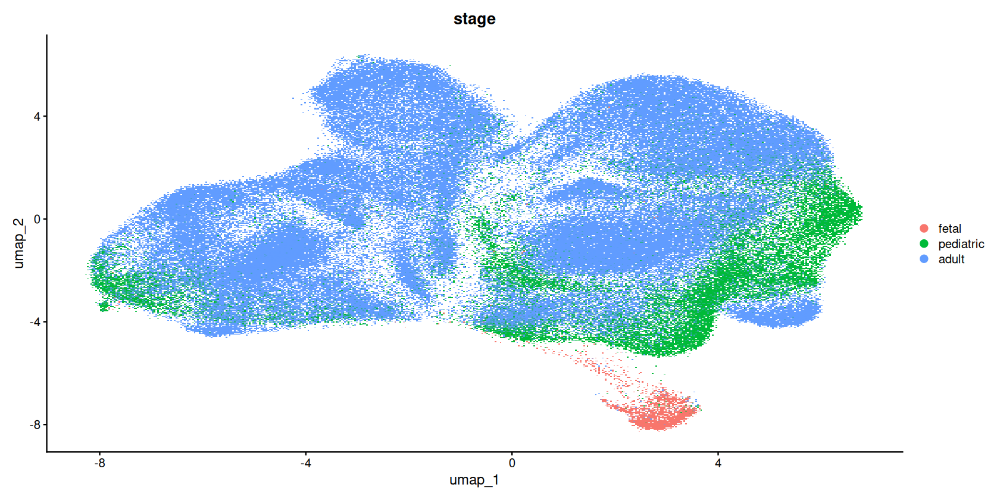

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



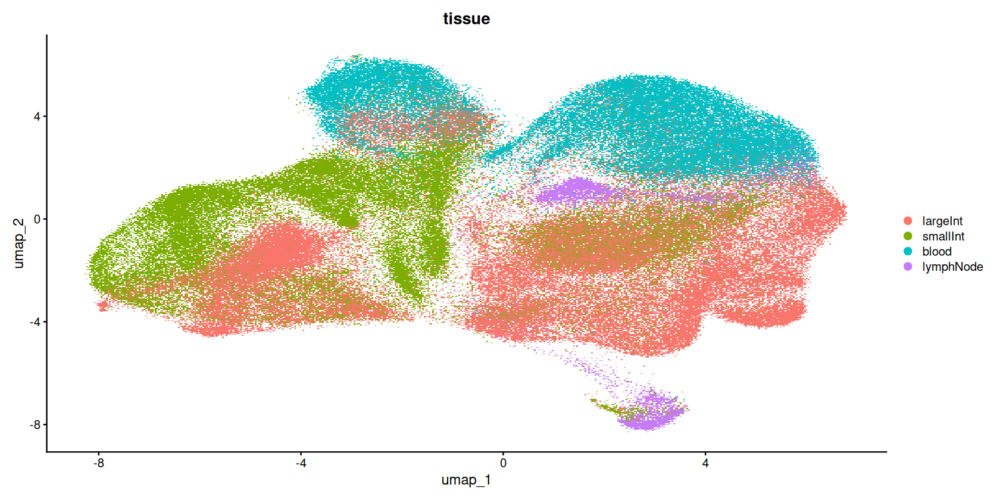

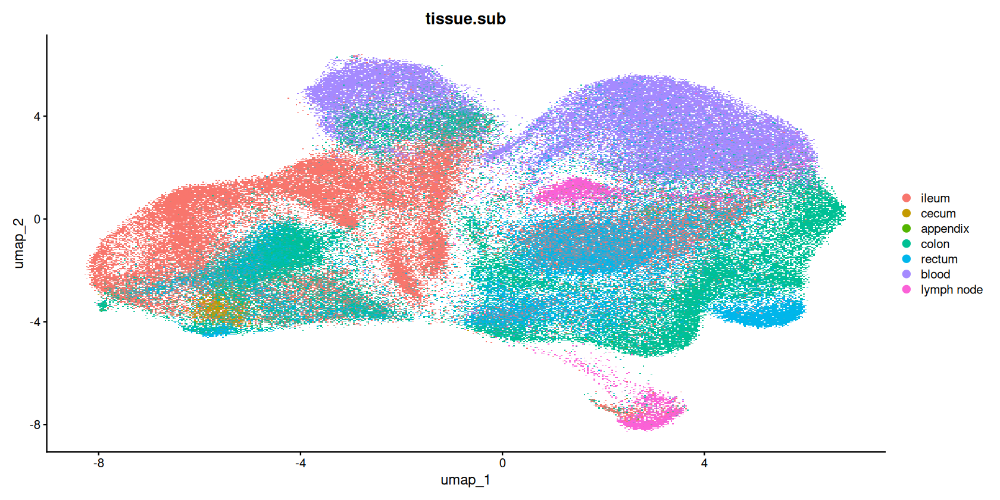

In [11]:
options(repr.plot.width = 14)
DimPlot(scIBD_CD4, group.by = "study")
DimPlot(scIBD_CD4, group.by = "subject")
DimPlot(scIBD_CD4, group.by = "stage")
DimPlot(scIBD_CD4, group.by = "tissue")
DimPlot(scIBD_CD4, group.by = "tissue.sub")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



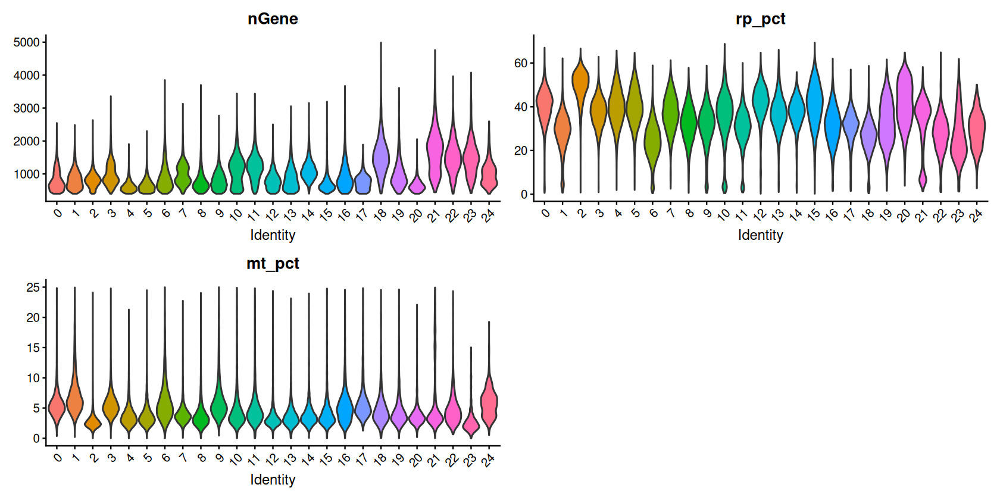

In [17]:
VlnPlot(scIBD_CD4, features = c("nGene", "rp_pct", "mt_pct"), ncol = 2, pt.size = 0)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



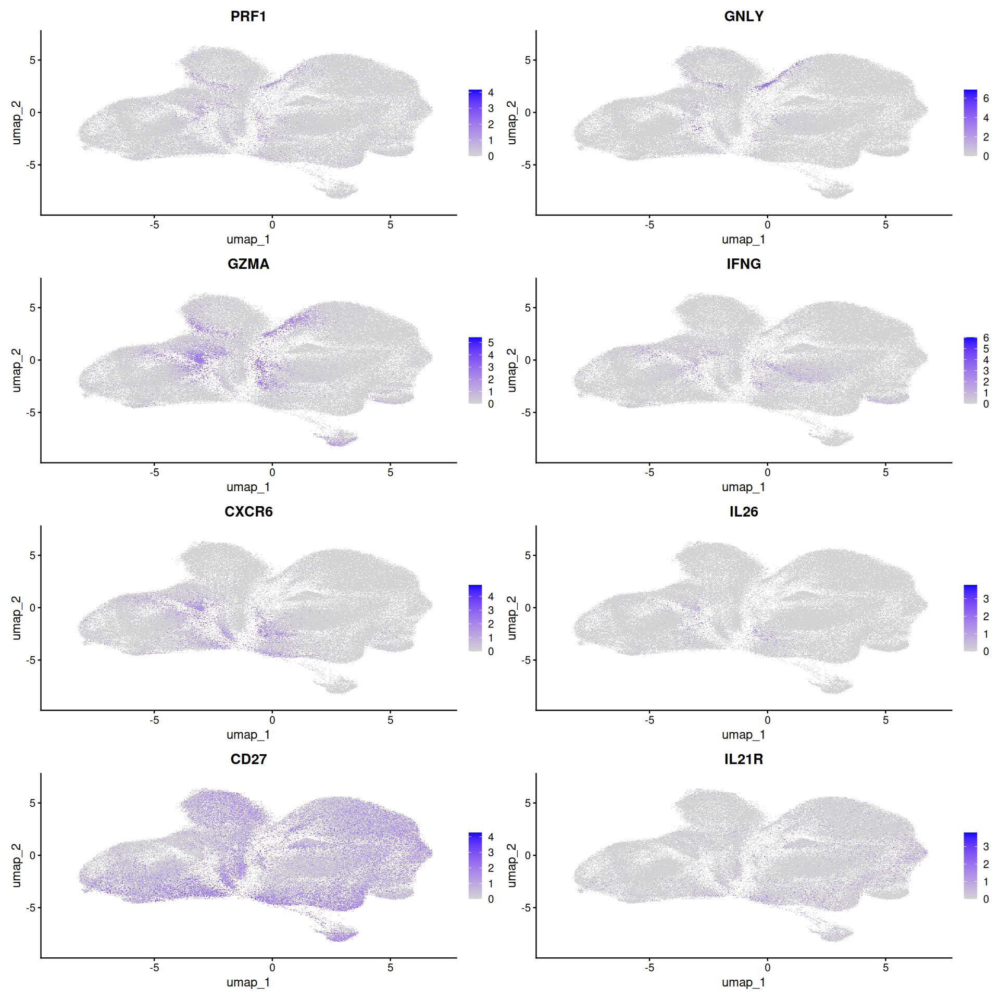

In [18]:
options(repr.plot.width = 16, repr.plot.height = 16)
FeaturePlot(scIBD_CD4, features = c("PRF1", "GNLY","GZMA","IFNG","CXCR6","IL26","CD27","IL21R"), ncol = 2)

In [19]:
cd4_ctl_sig  <- c(

    'GZMA', 'CTSH', 'IFNG', 'CCL4', 'HLA-DRB5', 'ZEB2', 'CHN1', 'IL12RB2', 'TESC', 'ADAM12', 'CPNE7', 'IL26',
    'GZMH', 'DAPK2', 'GZMB', 'COL5A3', 'OASL', 'NCR3', 'MCOLN2', 'GNLY', 'CSF2', 'MSC', 'GOLIM4', 
    'LINC02694', 'IL17A', 'GZMK', 'CDCA7', 'LINC00299', 'GPR34', 'LINC02384', 'FASLG', 'IL22', 'PKIG', 
    'APOBEC3H', 'PPARG', 'NUSAP1', 'SLC27A2', 'MSC-AS1', 'LYN', 'NTRK2', 'HDGFL3', 'MREG', 'MKI67', 
    'HLA-DQA2', 'KLRD1', 'SLAMF8', 'FSD1', 'TMPRSS3', 'PCLAF', 'TYMS', 'TOP2A', 'SETBP1', 'TOGARAM2', 'TPX2', 
    'IL17F', 'AL139393.3', 'PROK2', 'RHOU', 'MYO7A', 'EOMES', 'CENPE', 'TK1', 'KIF11', 'NCAPH', 'FCRL6', 'TIAM2', 
    'RRM2', 'CDK1', 'CDT1', 'RCAN2', 'SYNGR3', 'PALLD', 'BIRC5', 'ASPM', 'C3orf14', 'WWTR1', 'PLEKHG3', 'OTUB2', 
    'FES', 'ELOVL4', 'ADGRG5', 'CCNA2', 'UBE2C', 'EVC', 'KIFC1', 'TNS3', 'CD160', 'CCNB2', 'KIF23', 'AC243829.4', 
    'NCAPG', 'DOCK5', 'KIF2C', 'AC092580.4', 'P4HA2', 'CDCA2', 'PKMYT1', 'UHRF1', 'GTSE1', 'GPR27', 'DPF3', 
    'LINC02446', 'DLGAP5', 'ZNF683', 'CDC20', 'TROAP', 'AURKB', 'CEND1', 'CENPA', 'NMU', 'BUB1B', 'MELK', 'FOXM1', 
    'DEPDC1B', 'HMMR', 'CDCA5', 'CKAP2L', 'SHCBP1', 'RGS9', 'KIF14', 'KIF15', 'CDCA3', 'RAD51', 'PLK1', 'SPC25', 
    'CCR1', 'KIF4A', 'HJURP', 'NUGGC', 'PRR11', 'ESCO2', 'CDC45', 'MND1', 'TENM4', 'PIF1', 'HRH4', 'TP73', 'ADGRG1', 
    'PXDC1', 'SPC24', 'DIAPH3', 'E2F2', 'ANLN', 'MCM10', 'ATP8B4', 'SKA1', 'AL139393.2', 'DEPDC1', 'E2F8', 'SKA3', 
    'PDLIM4', 'GLDC', 'PBK', 'NCS1', 'KIF20A', 'TP63', 'CES1', 'KIF18B', 'HIST1H3G', 'KLHL13', 'HIST1H3C', 'BATF3', 
    'SOX5', 'E2F7', 'ARNTL2', 'CDC25A', 'ZBED2', 'MPPED2', 'FAM111B', 'GLB1L2', 'AL133405.2', 'NTRK1', 'FAM72B', 
    'TRPC3', 'AL356234.2', 'HMHB1', 'AC013460.1', 'CDC25C', 'KRT86', 'KLRC4', 'TYMSOS', 'KLRC1', 'ESPL1', 'ODAPH', 
    'RASGEF1A', 'PKHD1', 'KLRC2'
)

In [20]:
DefaultAssay(scIBD_CD4)  <- "RNA"
cd4_ctl_sig_filt  <- cd4_ctl_sig[which(cd4_ctl_sig %in% rownames(PanGI_CD4@assays$RNA))]
PanGI_CD4  <- AddModuleScore(PanGI_CD4, features = list(cd4_ctl_sig),
  name     = "CTL_score")

Warning message:
“The following features are not present in the object: LINC02694, LINC02384, MSC-AS1, HDGFL3, PCLAF, TOGARAM2, AL139393.3, ADGRG5, AC243829.4, AC092580.4, LINC02446, ADGRG1, AL139393.2, AL133405.2, TRPC3, AL356234.2, AC013460.1, TYMSOS, ODAPH, not searching for symbol synonyms”


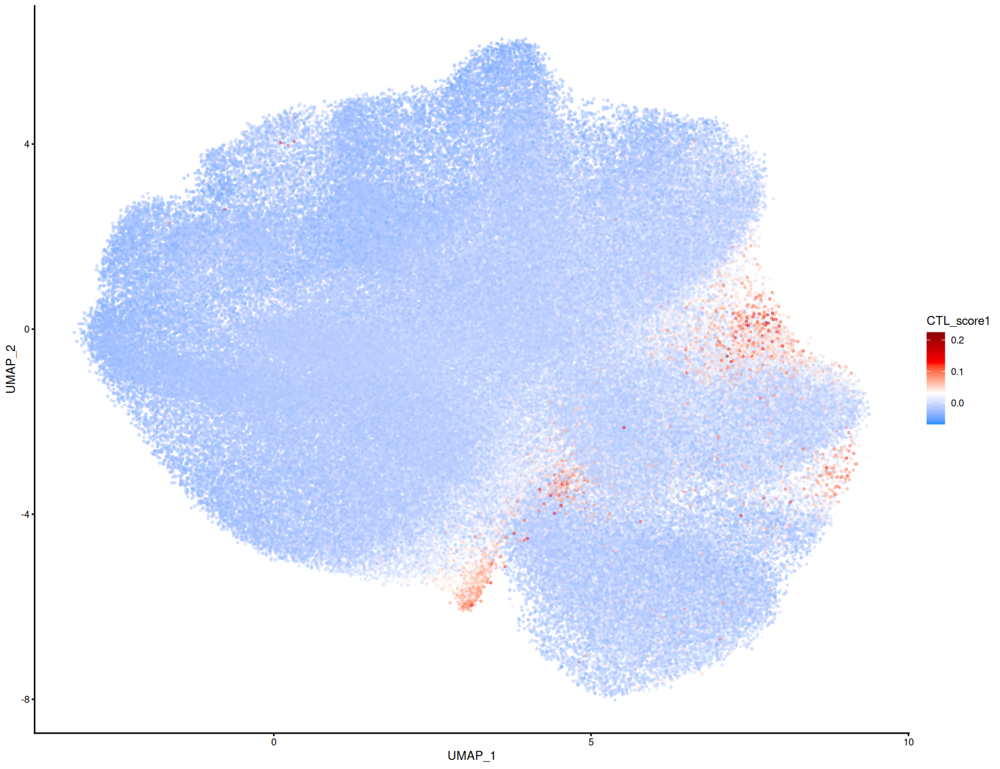

In [21]:
options(repr.plot.width = 13, repr.plot.height = 10)
scIBD_CD4@meta.data  %>% 
ggplot(aes(x = UMAP_1, y = UMAP_2)) +
geom_point(aes(color = CTL_score1), alpha = 0.4, size = 0.5) +
theme_classic() +
scale_colour_gradientn(
    colours = c("dodgerblue", "white", "red","darkred"))

In [22]:
saveRDS(scIBD_CD4, file = "scIBD_CD4.rds")

In [43]:
scIBD_CD4 <- readRDS("scIBD_CD4.rds")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



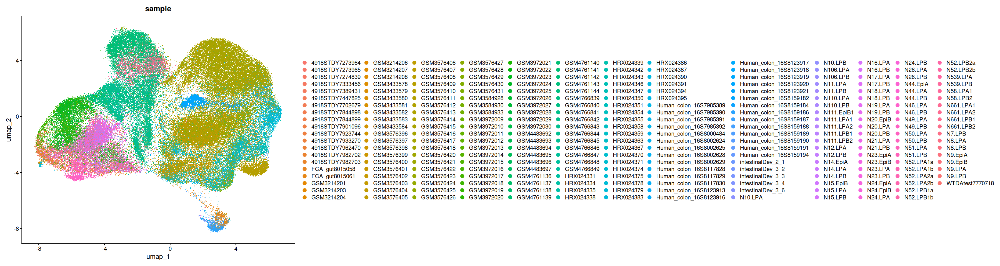

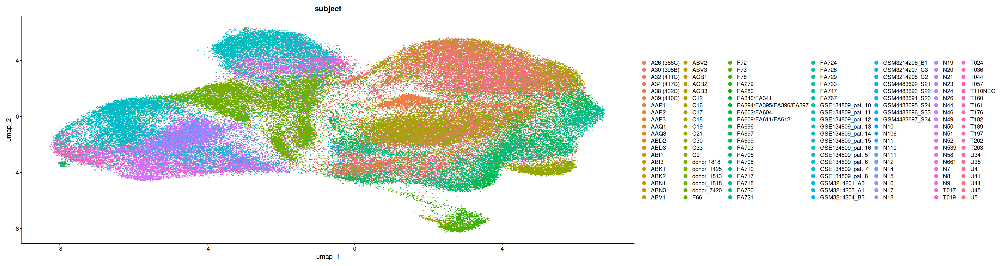

In [44]:
DimPlot(scIBD_CD4, group.by = "sample")
DimPlot(scIBD_CD4, group.by = "subject")

### STACAS Integration

In [3]:
library(STACAS)

Excluding 37 datasets with < 100 cells

You may alter this behavior by setting the min.sample.size parameter

Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse used at -2.2001”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“neighborhood radius 0.3222”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“reciprocal condition number  0”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“There are other near singularities as well. 0.090619”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse used at -2.783”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“neighborhood radius 0.49968”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“reciprocal condition number  7.0067e-16”
Warning 

Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“There are other near singularities as well. 0.090619”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse used at -2.3927”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“neighborhood radius 0.30103”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“reciprocal condition number  2.534e-16”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse used at -2.5846”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“neighborhood radius 0.4982”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“reciprocal condition number  3.0763e-16”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“There are other ne

Warning message:
“Number of dimensions changing from 50 to 20”
Warning message:
“Number of dimensions changing from 50 to 20”
Warning message:
“Number of dimensions changing from 50 to 20”
Warning message:
“Number of dimensions changing from 50 to 20”
Warning message:
“Number of dimensions changing from 50 to 20”
Warning message:
“Number of dimensions changing from 50 to 20”
Warning message:
“Number of dimensions changing from 50 to 20”
Warning message:
“Number of dimensions changing from 50 to 20”
Warning message:
“Number of dimensions changing from 50 to 20”
Warning message:
“Number of dimensions changing from 50 to 20”
Warning message:
“Number of dimensions changing from 50 to 20”
Warning message:
“Number of dimensions changing from 50 to 20”
Building integration tree with base dataset: 6

Building integrated reference

Merging dataset 38 into 36

Extracting anchors for merged samples

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message

Finding integration vector weights

Integrating data


Integrating dataset 47 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 49 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 50 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 52 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 53 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 54 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 55 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 56 with 

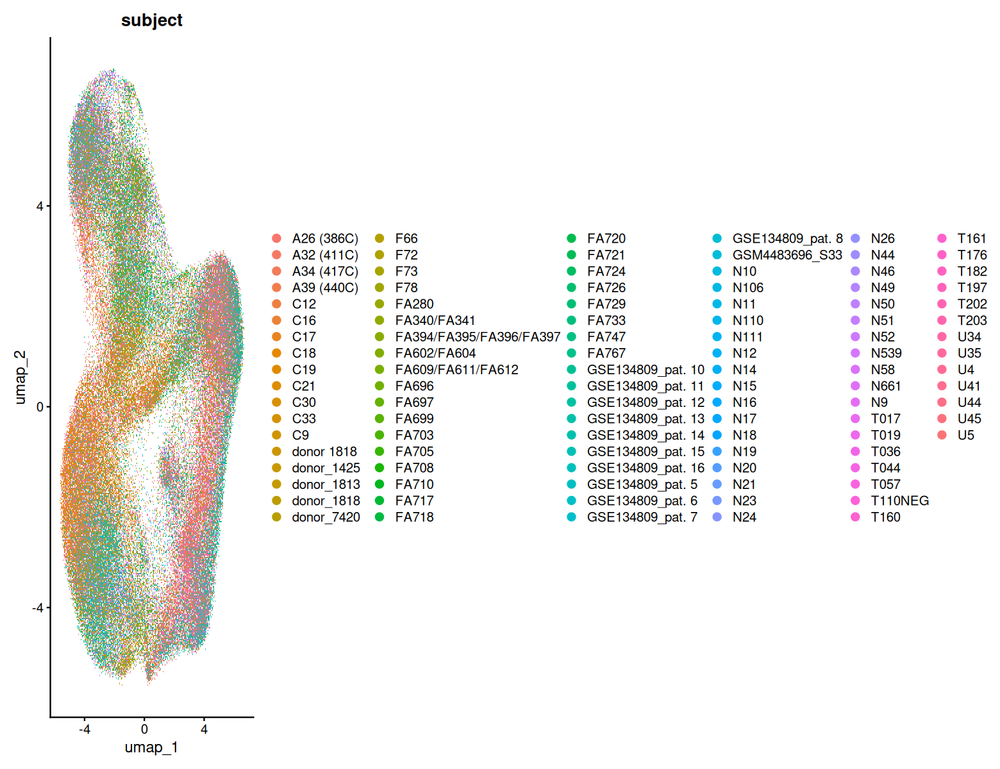

In [25]:
scIBD_CD4_int <- scIBD_CD4 %>% SplitObject(split.by = "subject") %>%
      Run.STACAS(dims = 1:20) %>%
      RunUMAP(dims = 1:20)
DimPlot(scIBD_CD4_int, group.by = "subject")
saveRDS(scIBD_CD4_int, file = "scIBD_CD4_integrated.rds")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



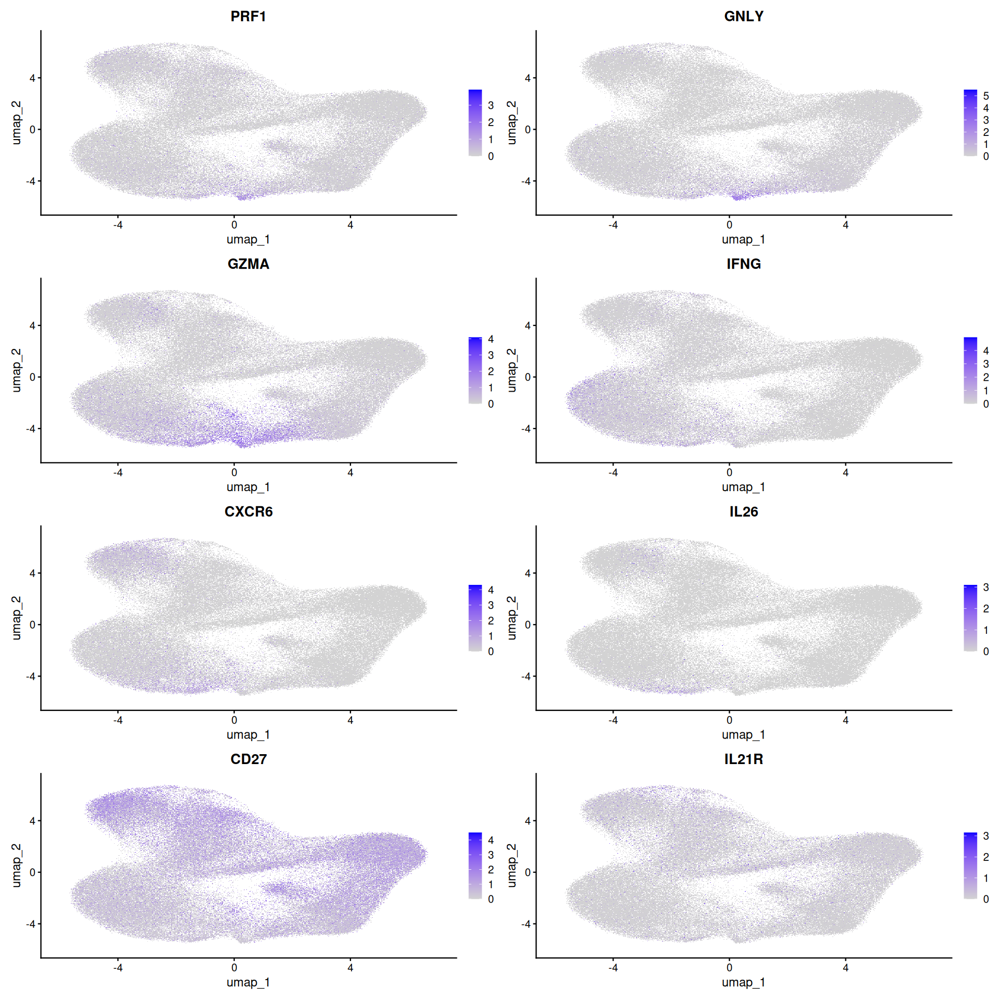

In [3]:
options(repr.plot.width = 16, repr.plot.height = 16)
FeaturePlot(scIBD_CD4_int, features = c("PRF1", "GNLY","GZMA","IFNG","CXCR6","IL26","CD27","IL21R"), min.cutoff = 0, ncol = 2)

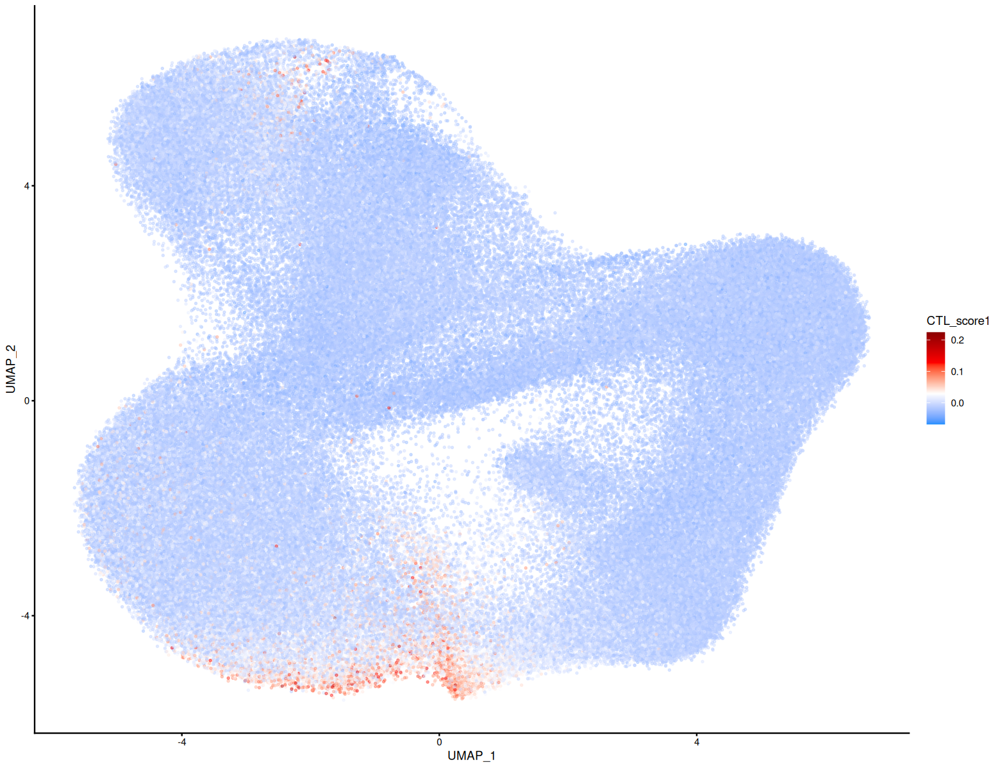

In [28]:
scIBD_CD4_int$UMAP_1 <- Embeddings(scIBD_CD4_int, reduction = "umap")[, 1]
scIBD_CD4_int$UMAP_2 <- Embeddings(scIBD_CD4_int, reduction = "umap")[, 2]

options(repr.plot.width = 13, repr.plot.height = 10)
scIBD_CD4_int@meta.data  %>% 
ggplot(aes(x = UMAP_1, y = UMAP_2)) +
geom_point(aes(color = CTL_score1), alpha = 0.4, size = 0.5) +
theme_classic() +
scale_colour_gradientn(
    colours = c("dodgerblue", "white", "red","darkred"))

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 187863
Number of edges: 4217213

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8300
Number of communities: 14
Elapsed time: 131 seconds


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



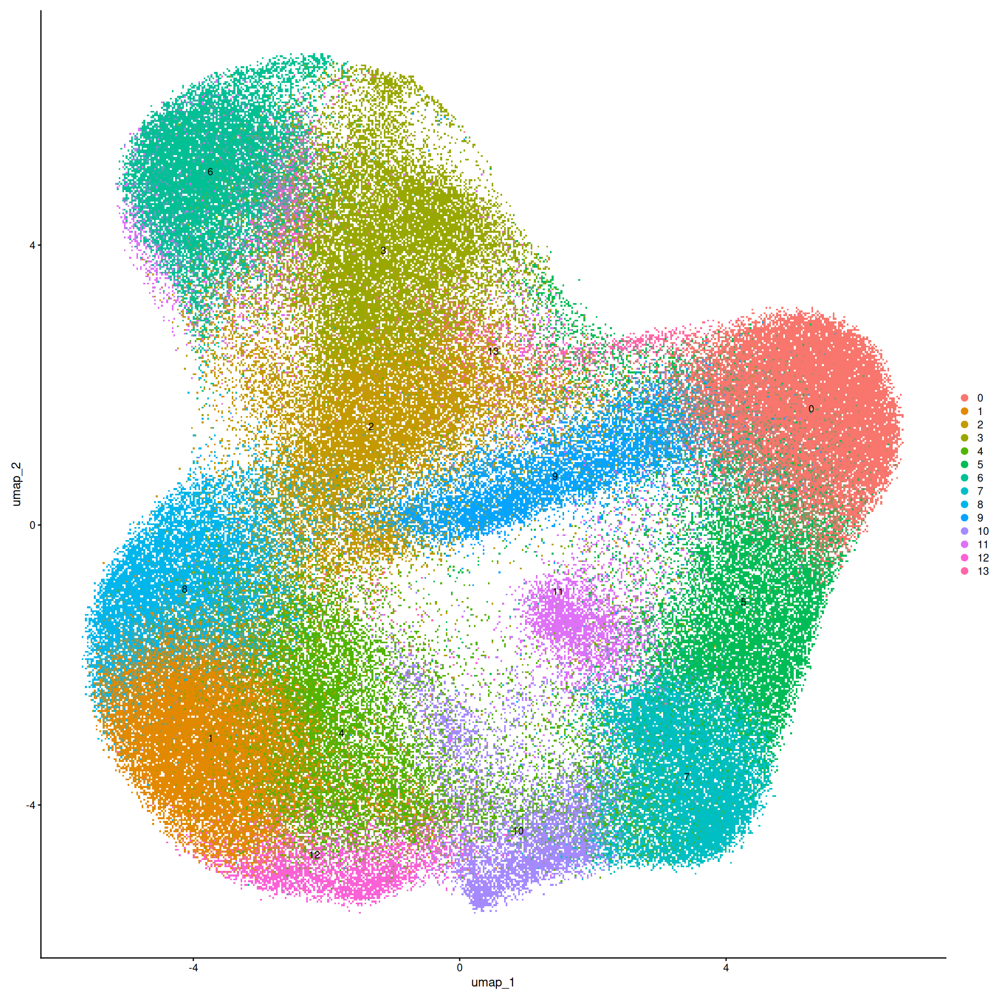

In [5]:
#scIBD_CD4_int <- FindNeighbors(scIBD_CD4_int)
scIBD_CD4_int <- FindClusters(scIBD_CD4_int, resolution = 0.8)
DimPlot(scIBD_CD4_int, reduction = "umap", label=T)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



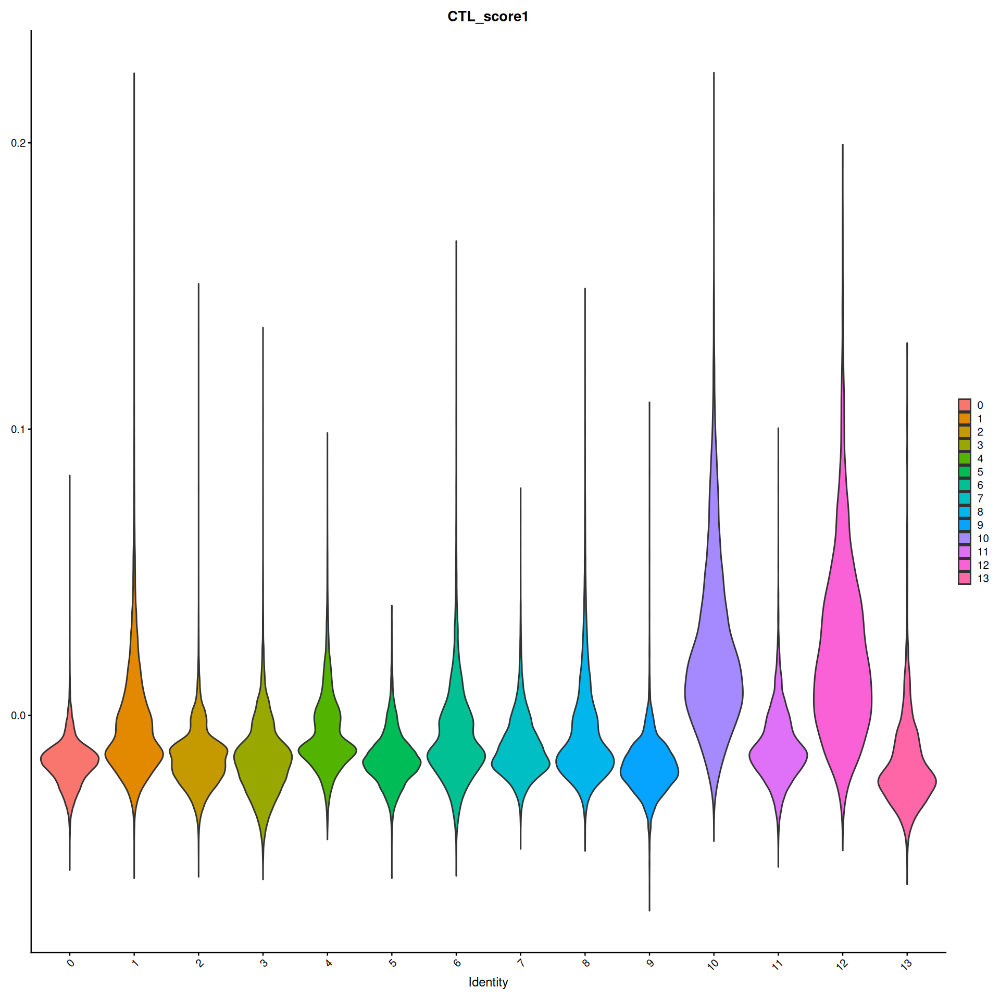

In [6]:
print(VlnPlot(scIBD_CD4_int, features = "CTL_score1", pt.size = 0))

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



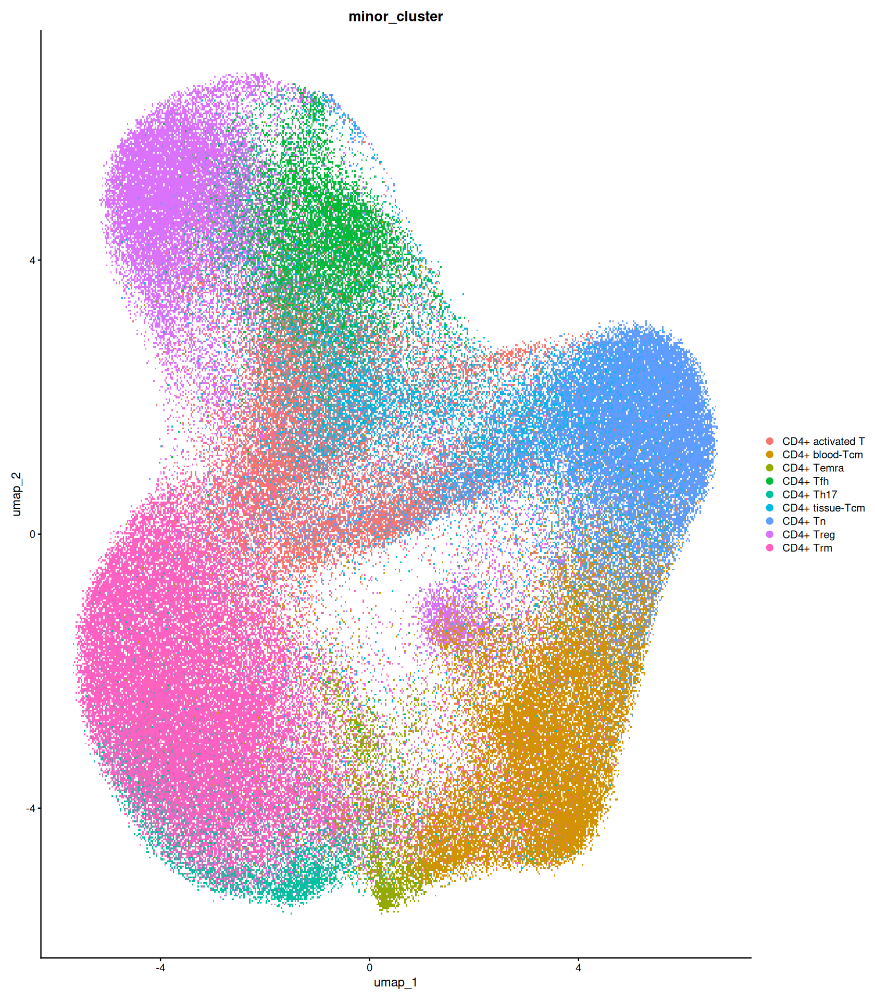

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



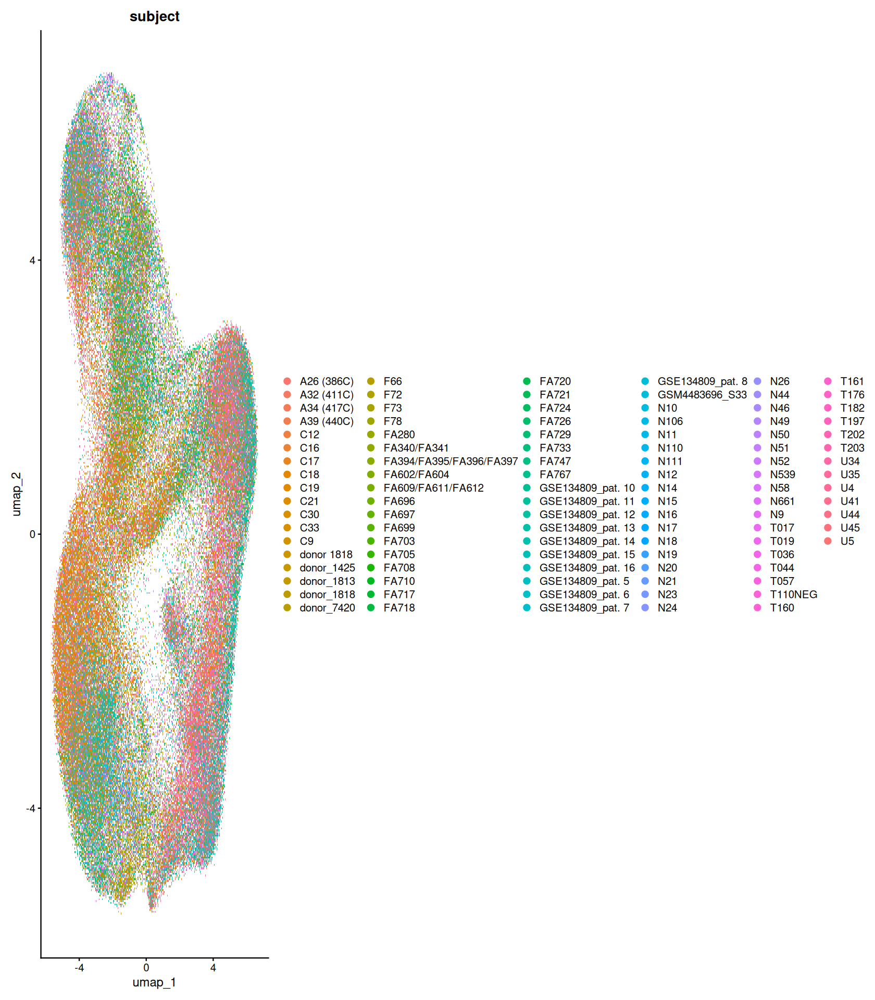

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



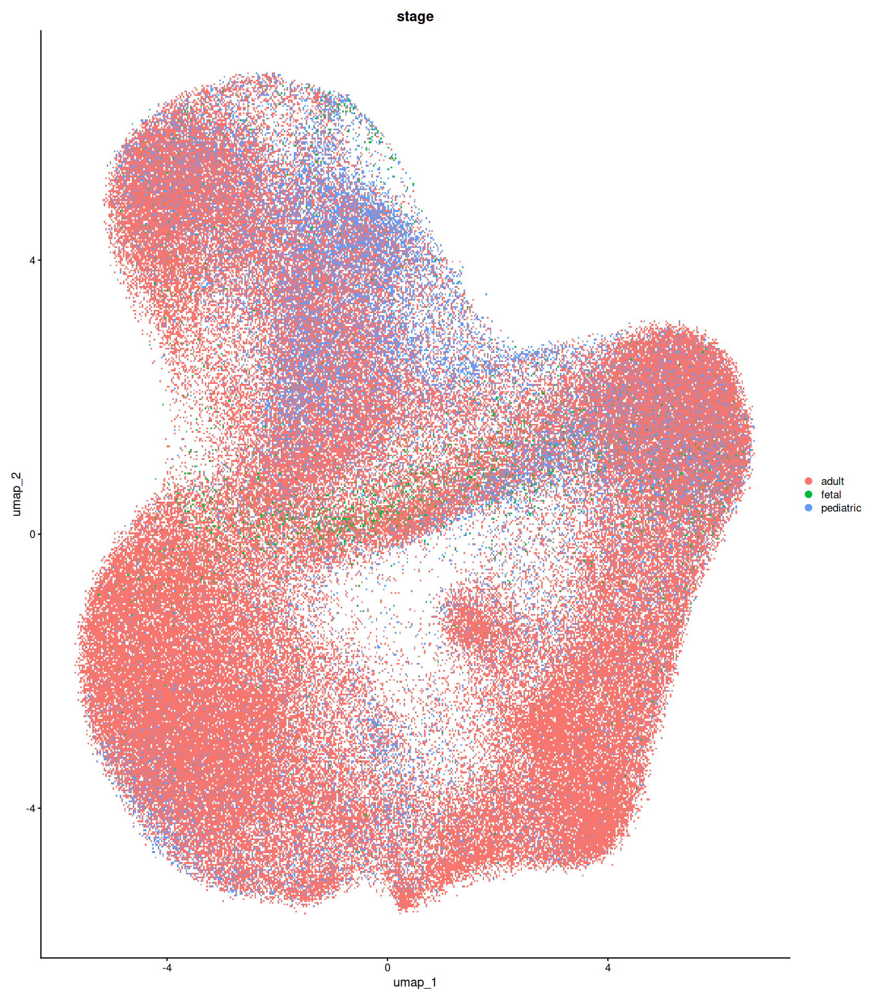

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



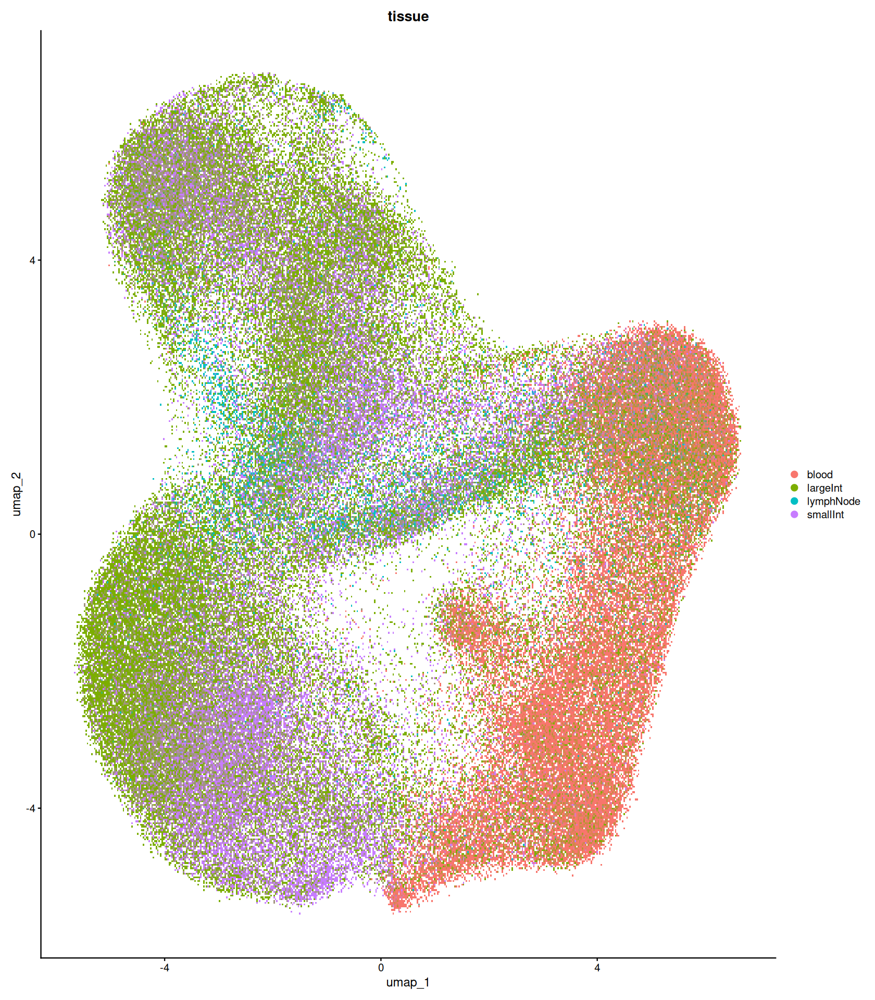

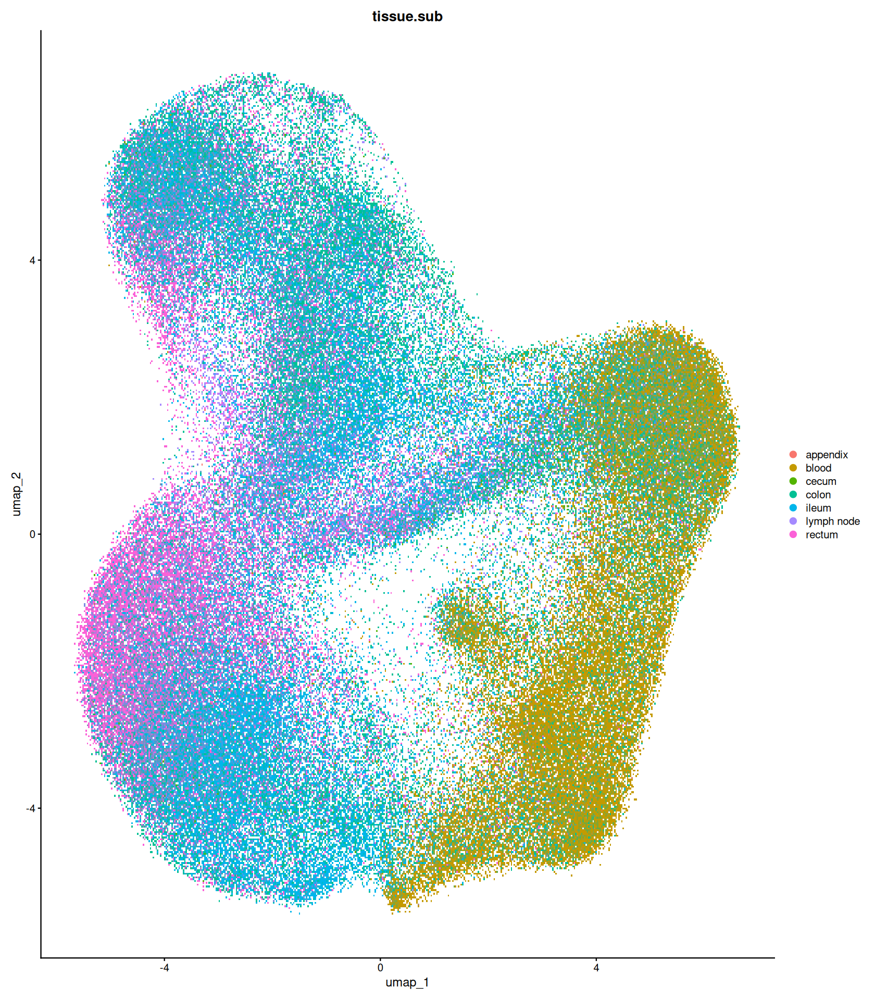

In [7]:
options(repr.plot.width = 14)
DimPlot(scIBD_CD4_int, group.by = "minor_cluster")
DimPlot(scIBD_CD4_int, group.by = "subject")
DimPlot(scIBD_CD4_int, group.by = "stage")
DimPlot(scIBD_CD4_int, group.by = "tissue")
DimPlot(scIBD_CD4_int, group.by = "tissue.sub")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



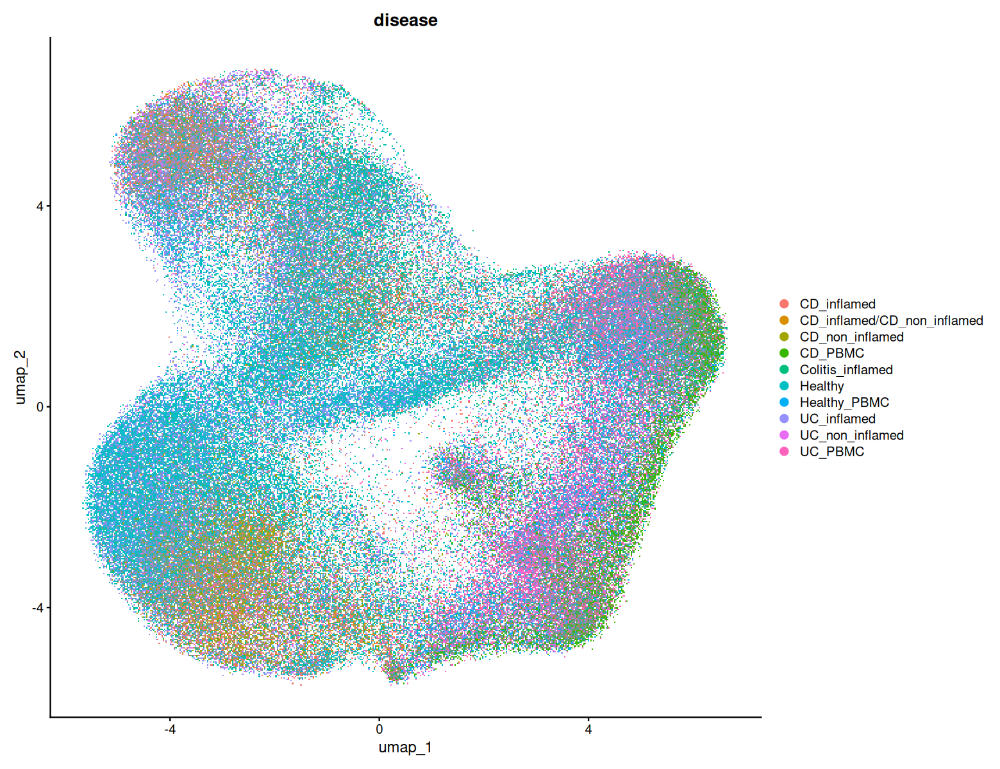

In [51]:
options(repr.plot.width = 13, repr.plot.height = 10)
DimPlot(scIBD_CD4_int, group.by = "disease")

In [13]:
saveRDS(scIBD_CD4_int, file = "scIBD_CD4_integrated.rds")

Found more than one class "package_version" in cache; using the first, from namespace 'SeuratObject'

Also defined by ‘alabaster.base’

Found more than one class "package_version" in cache; using the first, from namespace 'SeuratObject'

Also defined by ‘alabaster.base’



In [41]:
scIBD_CD4_int <- readRDS("scIBD_CD4_integrated.rds")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



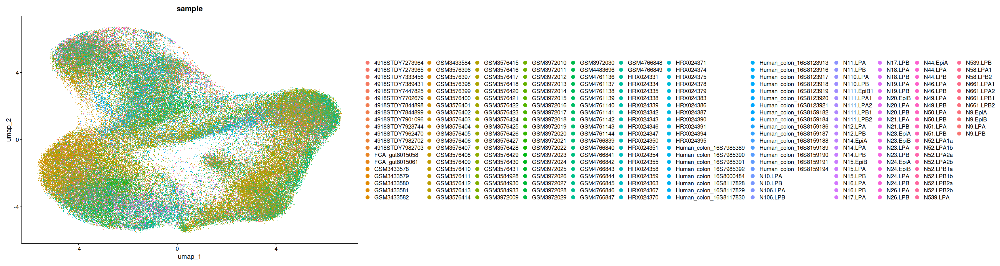

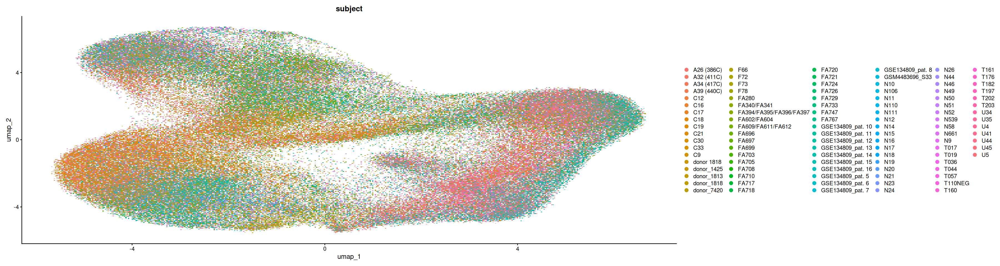

In [42]:
DimPlot(scIBD_CD4_int, group.by = "sample")
DimPlot(scIBD_CD4_int, group.by = "subject")

In [75]:
meta_data <- scIBD_CD4_int@meta.data

# Create grouped dataframe, calculate the frequencies of clusters
df4 <- meta_data %>% 
  group_by(subject, seurat_clusters) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n)) 

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by subject and seurat_clusters.
ℹ Output is grouped by subject.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(subject, seurat_clusters))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


In [76]:
# Control - all sums should be one
df4 %>% group_by(subject) %>% summarise(sum = sum(freq))

subject,sum
<chr>,<dbl>
A26 (386C),1
A32 (411C),1
A34 (417C),1
A39 (440C),1
C12,1
C16,1
C17,1
C18,1
C19,1


In [77]:
# As we've lost non-grouping variables, let's join them back
md_to_join <- meta_data %>% 
  dplyr::select(subject, tissue.sub, tissue, disease) %>% 
  unique()

df4  <- left_join(df4, md_to_join)


Joining with `by = join_by(subject)`
Warning message in left_join(df4, md_to_join):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1 of `x` matches multiple rows in `y`.
ℹ Row 117 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


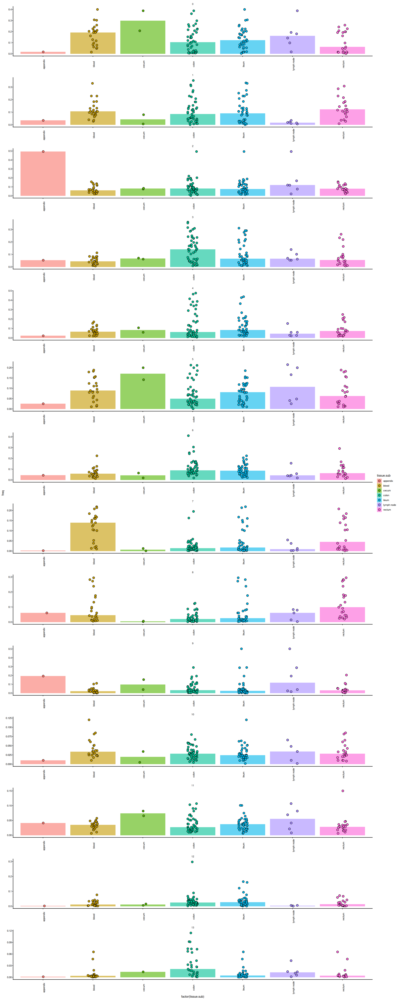

In [17]:
options(repr.plot.width = 20, repr.plot.height = 50)
df4 %>% 
unique  %>% 
  ggplot(aes(x = factor(tissue.sub), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = tissue.sub)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = tissue.sub), color = "black") + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 1) +
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))

Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


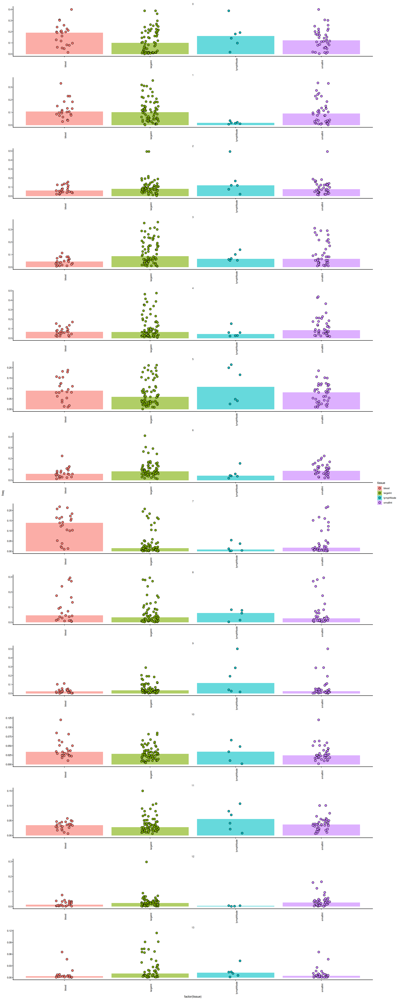

In [18]:
options(repr.plot.width = 20, repr.plot.height = 50)
df4 %>% 
unique  %>% 
  ggplot(aes(x = factor(tissue), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = tissue)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = tissue), color = "black") + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 1) +
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))

In [20]:
library(xlsx)

In [21]:
# identify cells
cluster_markers <- FindAllMarkers(scIBD_CD4_int, min.diff.pct = 0.1)
write.xlsx(cluster_markers, "cluster_markers.xlsx")

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Calculating cluster 8

Calculating cluster 9

Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Calculating cluster 10

Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Calculating cluster 11

Calculating cluster 12

Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Calculating cluster 13



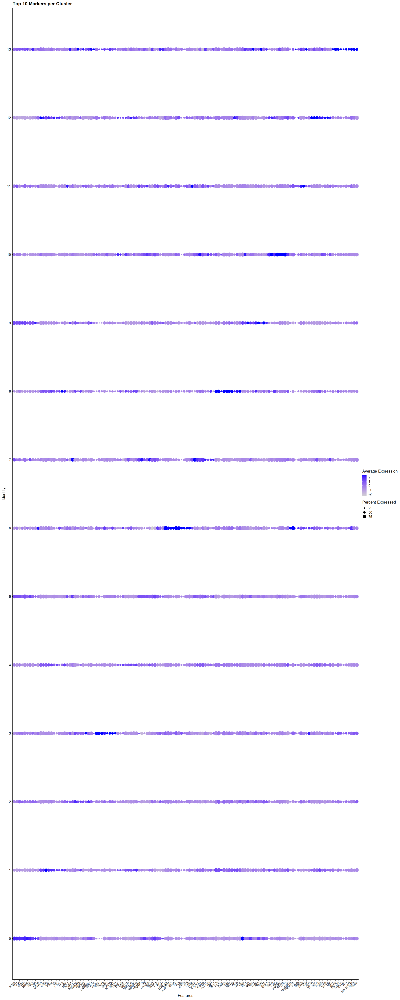

In [22]:
nr <- 0:13
for (i in nr)
{
  assign(paste0("cluster", i), subset(cluster_markers, cluster == i))
}

top10 <- cluster_markers %>% group_by(cluster) %>% top_n(n = 10, wt = avg_log2FC)

DotPlot(scIBD_CD4_int, features = unique(top10$gene)) +
  RotatedAxis() +
  theme(axis.text.x = element_text(size = 8)) +
  labs(title = "Top 10 Markers per Cluster")

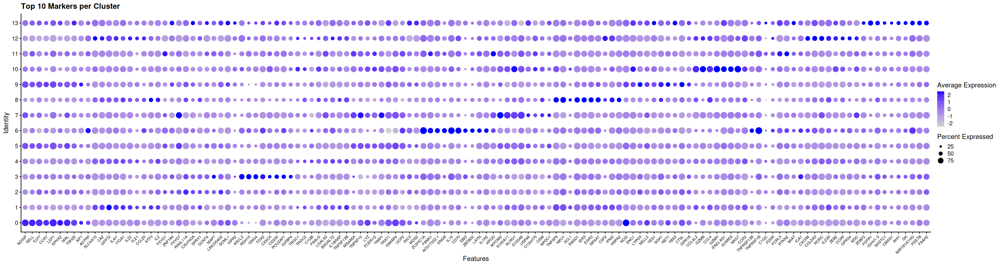

In [24]:
options(repr.plot.width = 30, repr.plot.height = 8)
DotPlot(scIBD_CD4_int, features = unique(top10$gene)) +
  RotatedAxis() +
  theme(axis.text.x = element_text(size = 8)) +
  labs(title = "Top 10 Markers per Cluster")

In [38]:
top10 |> filter(cluster == "10")

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
0.000000e+00,2.191736,0.875,0.594,0.000000e+00,10,CCL4L2
0.000000e+00,3.491357,0.819,0.621,0.000000e+00,10,GZMB
0.000000e+00,2.448306,0.852,0.670,0.000000e+00,10,CCL4
0.000000e+00,4.924724,0.867,0.739,0.000000e+00,10,GZMH
0.000000e+00,2.749052,0.758,0.875,0.000000e+00,10,IFNG-AS1
0.000000e+00,4.061267,0.738,0.845,0.000000e+00,10,EOMES
0.000000e+00,3.764586,0.882,0.776,0.000000e+00,10,NKG7
9.643507e-131,2.481179,0.719,0.838,9.643507e-128,10,ENC1
4.435607e-84,1.393086,0.708,0.842,4.435607e-81,10,CCR2


In [39]:
top10 |> filter(cluster == "12")

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
4.785781e-161,2.608756,0.612,0.736,4.785781e-158,12,CXCR6
1.947994e-88,2.442117,0.648,0.846,1.947994e-85,12,COL5A3
1.032798e-65,2.011830,0.648,0.813,1.032798e-62,12,RORC
3.587264e-58,2.049666,0.638,0.845,3.587264e-55,12,IL23R
9.682378e-40,2.538259,0.563,0.708,9.682378e-37,12,ZEB2
1.870502e-16,2.142541,0.485,0.767,1.870502e-13,12,CCR5
2.187181e-13,3.599741,0.506,0.655,2.187181e-10,12,GPR34
7.662654e-09,2.121754,0.508,0.610,7.662654e-06,12,CCL20
1.055520e-06,2.013846,0.516,0.737,1.055520e-03,12,MSC


Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


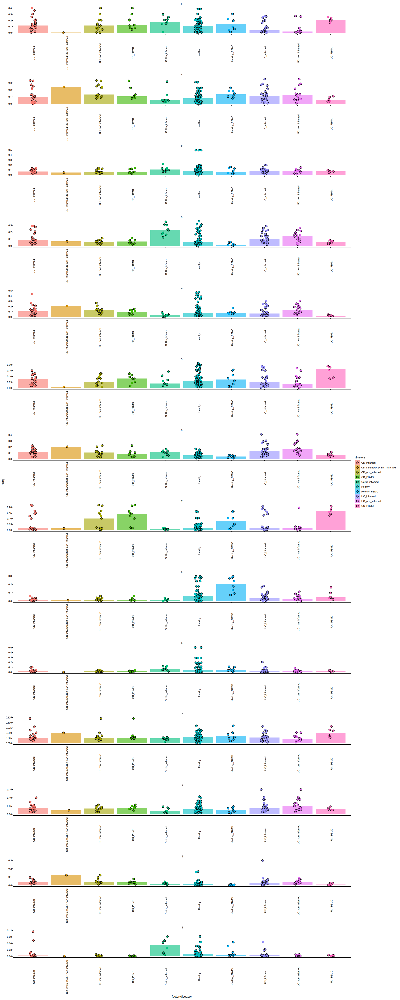

In [55]:
options(repr.plot.width = 20, repr.plot.height = 50)
df4 %>% 
unique  %>% 
  ggplot(aes(x = factor(disease), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = disease)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = disease), color = "black") + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 1) +
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))

In [101]:
PBMC <- df4 %>% dplyr::filter(tissue.sub == "blood")
PBMC_cl10 <- PBMC %>% dplyr::filter(seurat_clusters == "10")
PBMC_cl12 <- PBMC %>% dplyr::filter(seurat_clusters == "12")
ileum <- df4 %>% dplyr::filter(tissue.sub == "ileum")
ileum_cl10 <- ileum %>% dplyr::filter(seurat_clusters == "10")
ileum_cl12 <- ileum %>% dplyr::filter(seurat_clusters == "12")
colon <- df4 %>% dplyr::filter(tissue.sub == "colon")
colon_cl10 <- colon %>% dplyr::filter(seurat_clusters == "10")
colon_cl12 <- colon %>% dplyr::filter(seurat_clusters == "12")

Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


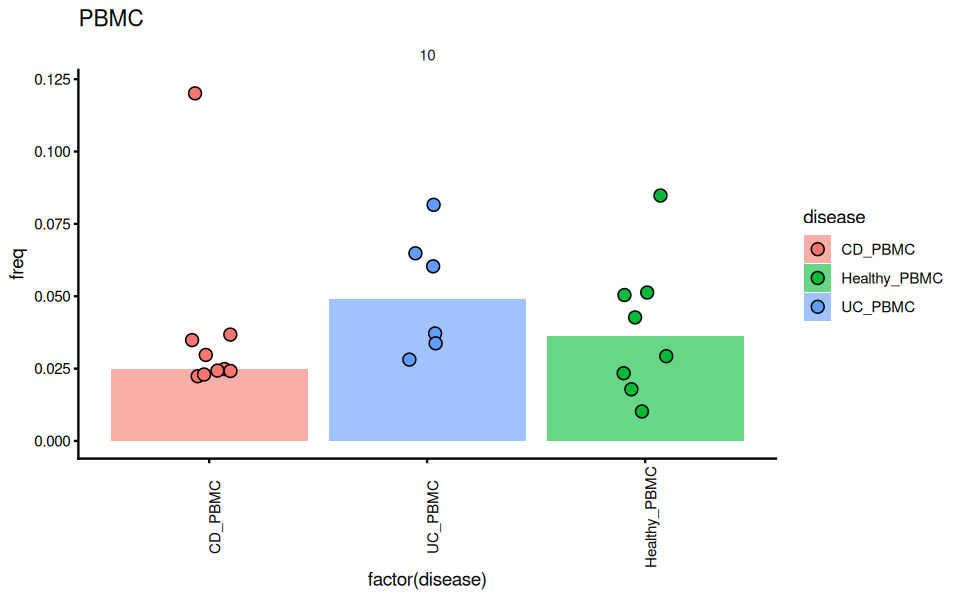

In [100]:
options(repr.plot.width = 8, repr.plot.height = 5)
PBMC_cl10 %>% 
unique  %>% 
  ggplot(aes(x = factor(disease), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = disease)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = disease), color = "black") + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 1) +
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))+
ggtitle("PBMC")+
scale_x_discrete(limits=c("CD_PBMC","UC_PBMC","Healthy_PBMC"))

Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


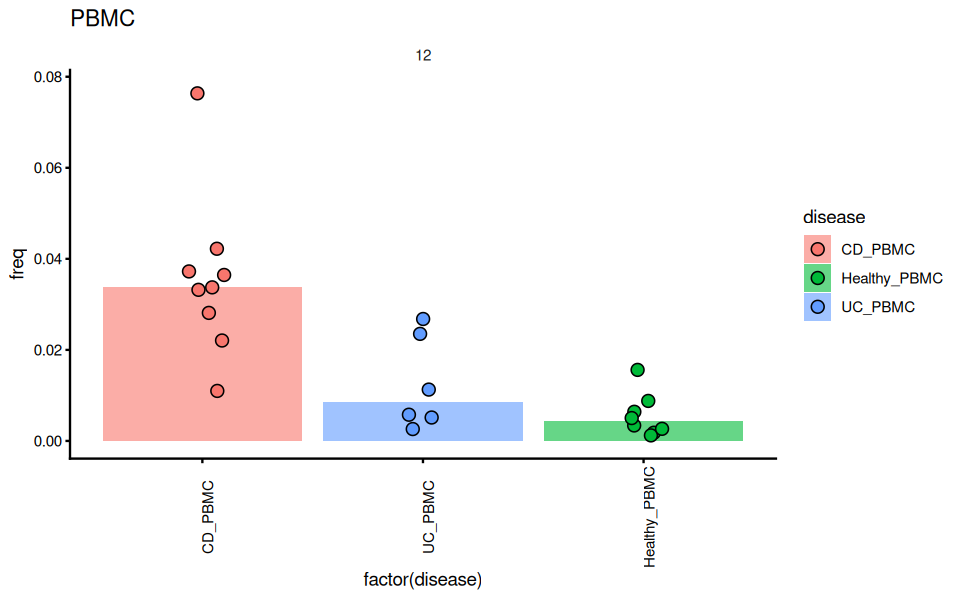

In [102]:
options(repr.plot.width = 8, repr.plot.height = 5)
PBMC_cl12 %>% 
unique  %>% 
  ggplot(aes(x = factor(disease), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = disease)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = disease), color = "black") + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 1) +
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))+
ggtitle("PBMC")+
scale_x_discrete(limits=c("CD_PBMC","UC_PBMC","Healthy_PBMC"))

Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


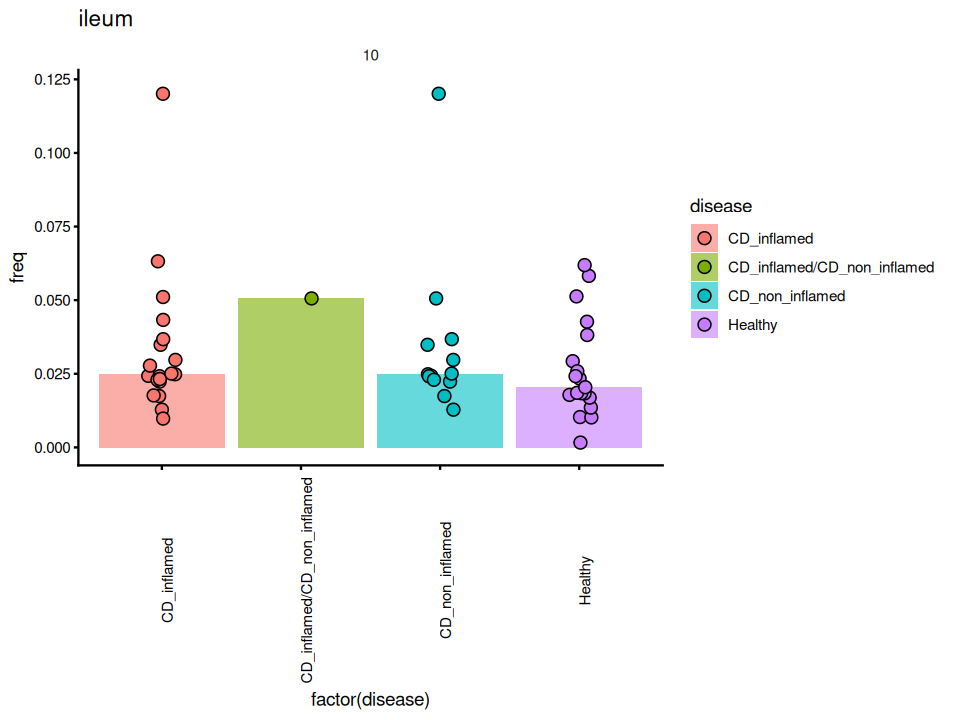

In [92]:
options(repr.plot.width = 8, repr.plot.height = 6)
ileum_cl10 %>% 
unique  %>% 
  ggplot(aes(x = factor(disease), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = disease)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = disease), color = "black") + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 1) +
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))+
ggtitle("ileum")

Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


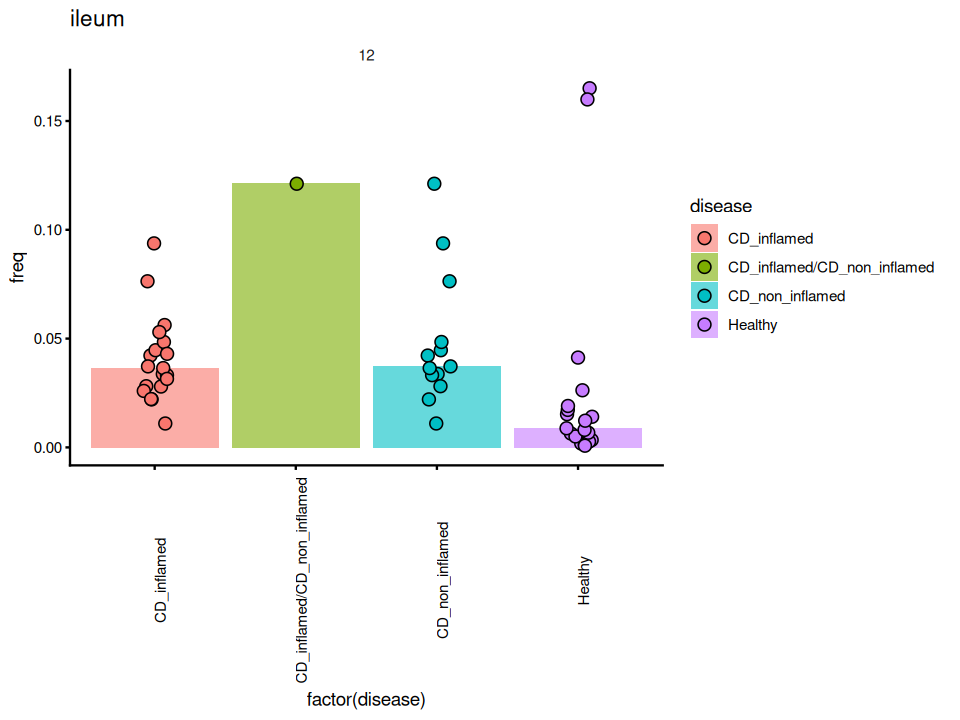

In [93]:
options(repr.plot.width = 8, repr.plot.height = 6)
ileum_cl12 %>% 
unique  %>% 
  ggplot(aes(x = factor(disease), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = disease)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = disease), color = "black") + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 1) +
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))+
ggtitle("ileum")

Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


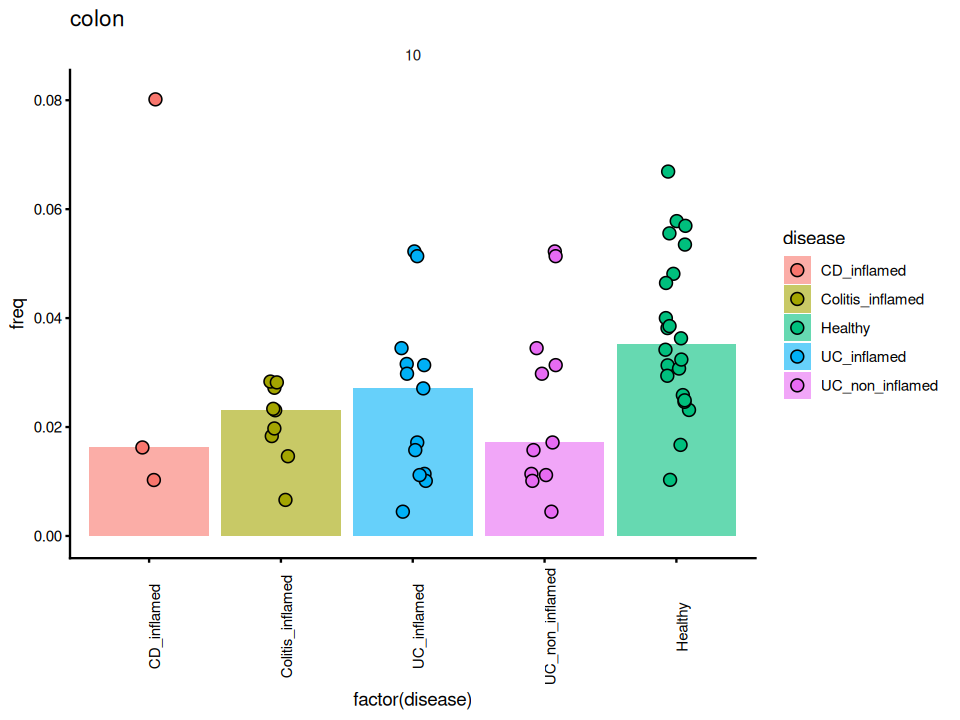

In [96]:
options(repr.plot.width = 8, repr.plot.height = 6)
colon_cl10 %>% 
unique  %>% 
  ggplot(aes(x = factor(disease), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = disease)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = disease), color = "black") + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 1) +
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))+
ggtitle("colon")+
scale_x_discrete(limits=c("CD_inflamed","Colitis_inflamed","UC_inflamed", "UC_non_inflamed", "Healthy"))

Warning message in geom_jitter(binaxis = "y", position = position_jitter(width = 0.1, :
“Ignoring unknown parameters: `binaxis` and `stackdir`”
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


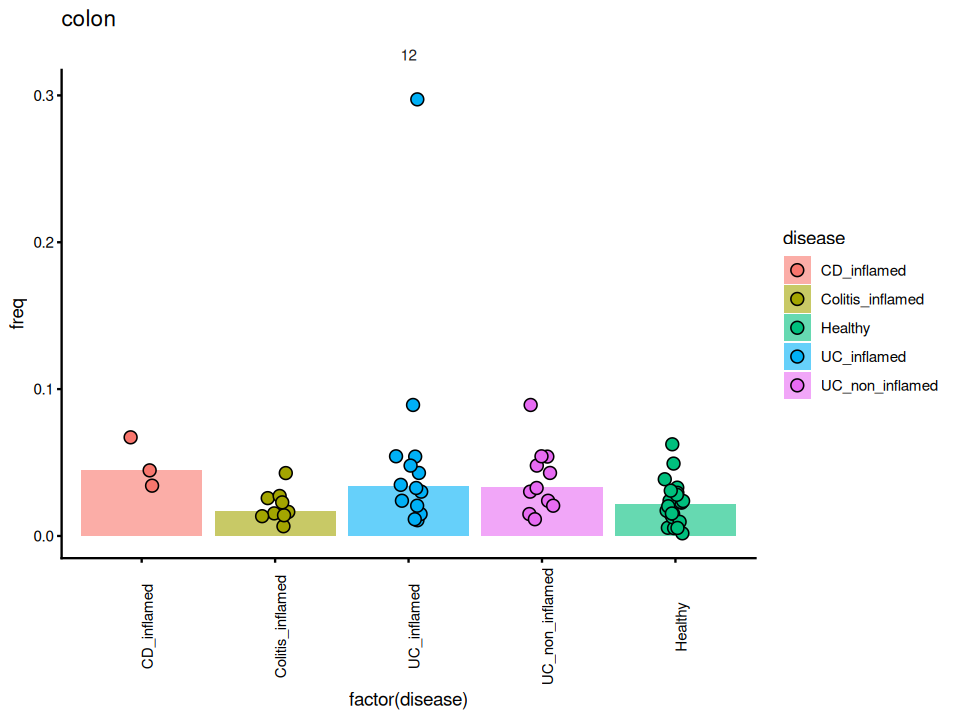

In [98]:
options(repr.plot.width = 8, repr.plot.height = 6)
colon_cl12 %>% 
unique  %>% 
  ggplot(aes(x = factor(disease), y = freq)) + # you can change the x to whatever variable you're interested in
   geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
 geom_bar(position='dodge', stat='summary', fun='median', alpha = 0.6, width = 0.9, aes(fill = disease)) +
   geom_jitter(binaxis='y', position=position_jitter(width = 0.1, height = 0), 
  size = 3, shape = 21, stackdir='center', aes(fill = disease), color = "black") + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 1) +
  theme_classic() +
 ylim(0,NA) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90))+
ggtitle("colon")+
scale_x_discrete(limits=c("CD_inflamed","Colitis_inflamed","UC_inflamed", "UC_non_inflamed", "Healthy"))

In [103]:
meta_data %>% 
  group_by(subject, sample)

sample,subject,study,nUMI,nGene,rp_pct,mt_pct,minor_cluster,major_cluster,UMAP_1,⋯,disease,RNA_snn_res.1,seurat_clusters,percent.rp,percent.mt,CTL_score1,integrated_snn_res.0.8,integrated_snn_res.0.5,integrated_snn_res.0.6,integrated_snn_res.0.7
<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,⋯,<chr>,<chr>,<fct>,<dbl>,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>
GSM4483696,GSM4483696_S33,"D. Corridoni et al., Nat Med, 2020",4328,1850,15.642328,3.604436,CD4+ Treg,CD4T,-3.138088,⋯,UC_inflamed,6,6,NA,NA,0.047502258,6,6,4,4
GSM4483696,GSM4483696_S33,"D. Corridoni et al., Nat Med, 2020",6343,2625,12.769982,4.729623,CD4+ Th17,CD4T,-1.610026,⋯,UC_inflamed,22,12,NA,NA,0.038848306,12,4,0,1
GSM4483696,GSM4483696_S33,"D. Corridoni et al., Nat Med, 2020",4664,1750,22.770155,6.239280,CD4+ Th17,CD4T,-2.926580,⋯,UC_inflamed,22,12,NA,NA,0.026827954,12,4,4,1
GSM4483696,GSM4483696_S33,"D. Corridoni et al., Nat Med, 2020",5446,1787,25.651854,7.785531,CD4+ Th17,CD4T,-3.249971,⋯,UC_inflamed,22,1,NA,NA,-0.022345816,1,0,0,0
GSM4483696,GSM4483696_S33,"D. Corridoni et al., Nat Med, 2020",3903,1591,15.424032,4.893671,CD4+ Th17,CD4T,-5.470907,⋯,UC_inflamed,22,1,NA,NA,0.095856722,1,0,3,0
GSM4483696,GSM4483696_S33,"D. Corridoni et al., Nat Med, 2020",5604,2008,20.753033,5.995717,CD4+ Th17,CD4T,-2.920802,⋯,UC_inflamed,22,6,NA,NA,0.095549718,6,6,4,4
GSM4483696,GSM4483696_S33,"D. Corridoni et al., Nat Med, 2020",1393,700,2.368988,22.756641,CD4+ activated T,CD4T,-2.888071,⋯,UC_inflamed,18,8,NA,NA,-0.006063413,8,0,3,0
GSM4483696,GSM4483696_S33,"D. Corridoni et al., Nat Med, 2020",1526,804,22.411533,10.091743,CD4+ Th17,CD4T,-0.949430,⋯,UC_inflamed,19,12,NA,NA,0.060271399,12,8,8,9
GSM4483696,GSM4483696_S33,"D. Corridoni et al., Nat Med, 2020",5844,2020,21.834360,8.555784,CD4+ Th17,CD4T,-2.459044,⋯,UC_inflamed,22,12,NA,NA,0.060323542,12,4,4,4


In [4]:
sessionInfo()

R version 4.5.2 (2025-10-31)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 24.04.5 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3 
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.26.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Europe/Prague
tzcode source: system (glibc)

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] STACAS_2.4.0                scCustomize_3.3.0          
 [3] ggpubr_0.6.0                scGate_1.7.0               
 [5] data.table_1.18.6.1         Sing